# Automatic Sleep Stage Classification with a Hybrid CNN-BiLSTM Architecture

This notebook implements an end-to-end pipeline for automatic sleep stage classification
on the Sleep-EDF Cassette dataset: multi-channel (EEG + EEG + EOG) preprocessing into STFT spectrograms,
a hybrid CNN-BiLSTM classifier, two ablation baselines (standalone CNN, standalone BiLSTM),
and a magnitude-pruned compressed variant. All figures are exported as vector PDF files to
`/kaggle/working/`.

The pipeline is split into two phases to manage Kaggle's GPU quota:

- **Phase D** — data download and preprocessing (no accelerator required)
- **Phase B** — model training and evaluation (GPU T4)

If a dataset preprocessed in a previous session is attached as input, Phase D is detected
automatically and skipped.

**Contents**
1. Environment Setup
2. Configuration and Cached-Data Detection
3. Data Preprocessing Pipeline (Function Definitions)
4. Phase D — Data Download and Preprocessing Execution
5. Exploratory Visualization of Preprocessing Impact
6. Phase B — Model Training
7. Model Evaluation and Visualization
8. Confusion Matrix
9. Model Compression: Pruning and Comparative Ablation Study

> **Update log (this version).** Switched the input from single-channel EEG to three channels
> (`EEG Fpz-Cz`, `EEG Pz-Oz`, `EOG horizontal`) -- see `EEG_CHANNELS` in Section 3 -- because the
> previous run's confusion matrices showed REM being confused with N1 in both the cropped and
> uncropped models, which is a textbook single-channel-EEG limitation: REM is defined largely by
> rapid eye movements that show up clearly in EOG but only ambiguously in EEG alone. This requires
> a full Phase D re-run (cached single-channel datasets are not compatible; a shape check in
> Section 6.6 will stop early with a clear message if you accidentally point at old cached data).
>
> Also fixed a latent bug in Section 9.3: pruning was being applied in place to `hybrid_model`
> without a `copy.deepcopy`, so `pruned_hybrid` and `hybrid_model` were silently the same object.
>
> **On the "uncropped looks healthier" observation:** this is real, but it is not evidence that
> cropping was a mistake -- it is a side effect of comparing metrics across two very differently
> composed test sets. The uncropped test set is roughly 70% Wake; the cropped one is not. Wake is
> the easiest class in this problem (large, redundant, low-ambiguity), so a model evaluated on a
> Wake-heavy set gets a smoother, monotonically-improving loss curve and inflated Accuracy/Kappa
> almost for free. Macro F1 -- the metric that treats all five stages equally -- was nearly tied
> between the two (0.722 cropped vs 0.731 uncropped, on the run analyzed for this update), and
> per-class results were mixed rather than a clean win for either side: the cropped model was
> clearly better at REM (F1 0.773 vs 0.748; recall 73.3% vs 67.7%) and slightly better at N2,
> while the uncropped model had better N1 recall and, unsurprisingly, much better Wake recall.
> Treat the "uncropped is healthier" training curve as a class-imbalance artifact to control for
> in the write-up, not as proof that wake-cropping should be abandoned.

## 1. Environment Setup

In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("Expected False during the CPU-only Phase D run; True once the accelerator is switched to GPU T4 for Phase B.")


CUDA available: True
Expected False during the CPU-only Phase D run; True once the accelerator is switched to GPU T4 for Phase B.


In [ ]:
# Install third-party libraries not preinstalled on Kaggle
!pip install mne codecarbon -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 402.7/402.7 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.3/71.3 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 71.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 68.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 114.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
sigstore 4.3.0 requires cryptography<49,>=42, but you have cryptography 50.0.1 which is incompatible.
pydrive2 1.21.3 requires cryptography<44, but you have cryptography 50.0.1 which is incompatible.
pyopenssl 24.2.1 requires cryptography<44,>=41.0.5, but you have 

In [ ]:
import mne, codecarbon
print(mne.__version__, codecarbon.__version__)


1.12.1 3.3.1


## 2. Configuration and Cached-Data Detection

Defines the working directory and checks whether preprocessed data or a training
checkpoint from a previous session is already attached to this notebook.

In [ ]:
import os, glob

# Directory where individual .npz files are saved during preprocessing
PROCESSED_DATA_DIR = "/kaggle/working/SleepData_Processed"
os.makedirs(PROCESSED_DATA_DIR, exist_ok=True)

print("Output directory set to:", PROCESSED_DATA_DIR)


Output directory set to: /kaggle/working/SleepData_Processed


### 2.1 Detecting a Previously Preprocessed Dataset

If a dataset from a previous run containing `*_preprocessed.npz` files is attached as
input, it is located automatically and Phase D below is skipped entirely.

In [ ]:
import os
import glob

# Exact paths to preprocessed data in attached Kaggle input
INPUT_BASE_DIR = "/kaggle/input/datasets/dikrahabsaoui/sc-preprocessed-230926/SleepData_Processed"
RAW_DATA_DIR = "/kaggle/input/datasets/dikrahabsaoui/sc-preprocessed-230926/full_data/sleep-edfx-1.0.0/sleep-cassette"

# Destination directories inside Kaggle's read-write environment
PROCESSED_DATA_DIR = "/kaggle/working/SleepData_Processed"
TRAIN_DIR = os.path.join(PROCESSED_DATA_DIR, "train")
VAL_DIR = os.path.join(PROCESSED_DATA_DIR, "val")
TEST_DIR = os.path.join(PROCESSED_DATA_DIR, "test")

# Check for existing preprocessed files
cached_npz_files = glob.glob(os.path.join(INPUT_BASE_DIR, "*.npz")) + glob.glob(os.path.join(INPUT_BASE_DIR, "**", "*.npz"), recursive=True)

if os.path.exists(TRAIN_DIR) and os.path.exists(VAL_DIR) and os.path.exists(TEST_DIR) and len(glob.glob(os.path.join(TRAIN_DIR, "*.npz"))) > 0:
    HAVE_CACHED_RECORDINGS = True
    NEEDS_SUBJECT_SPLIT = False
    FULL_DATA_ROOT = RAW_DATA_DIR
    print("SUCCESS: Pre-split dataset found in working directory!")
    print(f" Train path: {TRAIN_DIR}")
    print(f" Val path:   {VAL_DIR}")
    print(f" Test path:  {TEST_DIR}")
    print("Phase D downloading, preprocessing, and splitting will be completely skipped.")

elif len(cached_npz_files) > 0:
    HAVE_CACHED_RECORDINGS = True
    NEEDS_SUBJECT_SPLIT = True
    FULL_DATA_ROOT = RAW_DATA_DIR
    print(f"SUCCESS: Found {len(cached_npz_files)} cached .npz files in input directory!")
    print("Raw EDF re-downloading and MNE preprocessing will be SKIPPED.")
    print("Subject-wise splitting into train/val/test will run using these cached files.")

else:
    HAVE_CACHED_RECORDINGS = False
    NEEDS_SUBJECT_SPLIT = True
    FULL_DATA_ROOT = RAW_DATA_DIR
    print("WARNING: No preprocessed .npz files found. Full pipeline will download and preprocess raw data.")

SUCCESS: Found 306 cached .npz files in input directory!
Raw EDF re-downloading and MNE preprocessing will be SKIPPED.
Subject-wise splitting into train/val/test will run using these cached files.


### 2.2 Detecting a Previous Checkpoint

Same principle, applied to resuming training across sessions in Phase B.

In [ ]:
ckpt_candidates = glob.glob("/kaggle/input/*/base_model.pt") + glob.glob("/kaggle/input/*/*/base_model.pt")

if ckpt_candidates:
    import shutil
    shutil.copy(ckpt_candidates[0], "/kaggle/working/base_model.pt")
    print(f"Found a previous checkpoint at {ckpt_candidates[0]}, copied to /kaggle/working/base_model.pt.")
    print("Step B8's train_model will detect this and warm-start from it instead of a fresh model.")
else:
    print("No previous checkpoint found. Step B8 will train from scratch.")


No previous checkpoint found. Step B8 will train from scratch.


## 3. Data Preprocessing Pipeline (Function Definitions)

Functions used to convert raw PSG/Hypnogram EDF pairs into normalized spectrogram
sequences, saved as one compressed `.npz` file per subject.

In [ ]:
import os
import glob
import json
import numpy as np
import pandas as pd
import mne
from scipy.signal import stft
from tqdm import tqdm
from itertools import groupby

# Suppress MNE warnings for cleaner output
mne.set_log_level('ERROR')

# AASM stage mapping
STAGE_EVENT_ID = {
    'Sleep stage W': 1, 'Sleep stage 1': 2, 'Sleep stage 2': 3,
    'Sleep stage 3': 4, 'Sleep stage 4': 4, 'Sleep stage R': 5,
}
LABEL_NAMES = ['W', 'N1', 'N2', 'N3', 'REM']

# Channels used as input
EEG_CHANNELS = ['EEG Fpz-Cz', 'EEG Pz-Oz', 'EOG horizontal']
N_CHANNELS = len(EEG_CHANNELS)


In [ ]:
def crop_raw_to_main_sleep(raw, annotations, epoch_sec=30.0, wake_id=1, max_gap_epochs=120, buffer_epochs=60):
    """
    Finds the main sleep sequence by filtering out afternoon naps (gaps > 1hr).
    Automatically caps leading/trailing wake periods to 30 mins (60 epochs).
    Guarantees that NO valid sleep stages (N1, N2, N3, REM) are removed.
    """
    raw.set_annotations(annotations, emit_warning=False)
    events, _ = mne.events_from_annotations(raw, event_id=STAGE_EVENT_ID, chunk_duration=epoch_sec)

    labels = events[:, 2]
    sleep_idx = np.where(labels != wake_id)[0]

    if len(sleep_idx) == 0:
        return raw

    gaps = np.diff(sleep_idx) - 1

    split_points = np.where(gaps > max_gap_epochs)[0]
    seq_starts = np.insert(sleep_idx[split_points + 1], 0, sleep_idx[0])
    seq_ends = np.append(sleep_idx[split_points], sleep_idx[-1])

    seq_durations = seq_ends - seq_starts
    main_idx = np.argmax(seq_durations)
    main_start = seq_starts[main_idx]
    main_end = seq_ends[main_idx]

    start_idx = max(0, main_start - buffer_epochs)
    end_idx = min(len(events) - 1, main_end + buffer_epochs)

    tmin = start_idx * epoch_sec
    tmax = min((end_idx + 1) * epoch_sec, raw.times[-1])

    raw.crop(tmin=tmin, tmax=tmax)
    return raw

In [ ]:
def preprocess_edf_pair(psg_path, hyp_path, epoch_sec=30.0, sfreq=100.0):
    raw = mne.io.read_raw_edf(psg_path, preload=False, verbose=False)
    raw.pick(EEG_CHANNELS)
    annotations = mne.read_annotations(hyp_path)

    raw = crop_raw_to_main_sleep(raw, annotations, epoch_sec=epoch_sec)

    raw.load_data(verbose=False)
    raw.filter(l_freq=0.25, h_freq=40.0, fir_design='firwin', verbose=False)

    events, _ = mne.events_from_annotations(raw, event_id=STAGE_EVENT_ID, chunk_duration=epoch_sec)
    epochs = mne.Epochs(raw, events, event_id=STAGE_EVENT_ID, tmin=0.0,
                        tmax=epoch_sec - 1.0 / sfreq, baseline=None, preload=True,
                        on_missing='warn', verbose=False)

    data = epochs.get_data(copy=False)  # (n_epochs, N_CHANNELS, n_samples)
    labels = epochs.events[:, 2] - 1

    spectrograms = []
    for epoch in data:
        f, t, Zxx = stft(epoch, fs=sfreq, nperseg=100, noverlap=50, axis=-1)
        spec = np.log1p(np.abs(Zxx))
        freq_mask = (f >= 0.5) & (f <= 40.0)
        spectrograms.append(spec[:, freq_mask, :])

    X = np.array(spectrograms, dtype=np.float32)  # Shape: (N_epochs, N_CHANNELS, 40, 61)

    return X, labels.astype(np.int64)


In [ ]:
def find_pairs(data_dir):
    pairs = []
    for psg in sorted(glob.glob(os.path.join(data_dir, "**", "*PSG.edf"), recursive=True)):
        fname = os.path.basename(psg)

        # First 6 characters (e.g., "SC4001") uniquely identify the SC subject/night
        subject_id = fname[:6]

        matches = glob.glob(os.path.join(os.path.dirname(psg), f"{subject_id}*Hypnogram.edf"))
        if matches:
            pairs.append((psg, matches[0], subject_id))
    return pairs


In [ ]:
def compute_and_export_dataset_statistics(raw_data_dir, processed_data_dir, output_path):
    """
    Single source-of-truth dataset audit: scans the raw hypnogram annotations and the
    final processed .npz files once, and exports both to a JSON file so that every
    figure reads from exact values.
    """
    raw_hypnograms = glob.glob(os.path.join(raw_data_dir, "**", "*Hypnogram.edf"), recursive=True)
    # Strictly filter for Sleep Cassette (SC) hypnograms
    raw_hypnograms = [f for f in raw_hypnograms if os.path.basename(f).startswith("SC")]
    processed_files = glob.glob(os.path.join(processed_data_dir, "**", "*.npz"), recursive=True)

    stats = {"raw": None, "processed": None}

    if raw_hypnograms:
        before_counts = {'W': 0, 'N1': 0, 'N2': 0, 'N3': 0, 'REM': 0}
        before_durations, before_max_wake = [], []

        for hyp_path in raw_hypnograms:
            ann = mne.read_annotations(hyp_path)
            before_durations.append(float((ann.onset[-1] + ann.duration[-1]) / 3600))

            curr_wake_block, max_wake = 0.0, 0.0
            for desc, dur in zip(ann.description, ann.duration):
                if desc == 'Sleep stage W':
                    before_counts['W'] += int(dur // 30)
                    curr_wake_block += dur / 3600
                    max_wake = max(max_wake, curr_wake_block)
                else:
                    curr_wake_block = 0.0
                    if desc == 'Sleep stage 1': before_counts['N1'] += int(dur // 30)
                    elif desc == 'Sleep stage 2': before_counts['N2'] += int(dur // 30)
                    elif desc in ['Sleep stage 3', 'Sleep stage 4']: before_counts['N3'] += int(dur // 30)
                    elif desc == 'Sleep stage R': before_counts['REM'] += int(dur // 30)
            before_max_wake.append(max_wake)

        total_before = sum(before_counts.values()) or 1
        stats["raw"] = {
            "n_recordings": len(raw_hypnograms),
            "epoch_counts": before_counts,
            "epoch_percentages": {k: round(100 * v / total_before, 2) for k, v in before_counts.items()},
            "durations_hours": before_durations,
            "max_continuous_wake_hours": before_max_wake,
        }

    if processed_files:
        after_counts_raw = {0: 0, 1: 0, 2: 0, 3: 0, 4: 0}
        after_durations, after_max_wake = [], []

        for npz_path in processed_files:
            data = np.load(npz_path)
            y = data['y']
            after_durations.append(float(len(y) * 30 / 3600))
            unique, counts = np.unique(y, return_counts=True)
            for u, c in zip(unique, counts):
                after_counts_raw[int(u)] += int(c)
            wake_lengths = [len(list(g)) for val, g in groupby(y == 0) if val]
            after_max_wake.append(float((max(wake_lengths) if wake_lengths else 0) * 30 / 3600))

        after_counts = {'W': after_counts_raw[0], 'N1': after_counts_raw[1], 'N2': after_counts_raw[2],
                        'N3': after_counts_raw[3], 'REM': after_counts_raw[4]}
        total_after = sum(after_counts.values()) or 1
        stats["processed"] = {
            "n_recordings": len(processed_files),
            "epoch_counts": after_counts,
            "epoch_percentages": {k: round(100 * v / total_after, 2) for k, v in after_counts.items()},
            "durations_hours": after_durations,
            "max_continuous_wake_hours": after_max_wake,
        }

    with open(output_path, "w") as f:
        json.dump(stats, f, indent=2)

    print(f"Dataset statistics exported to {output_path}")
    return stats


In [ ]:
def build_and_save_recordings(data_dir, save_dir):
    pairs = find_pairs(data_dir)
    os.makedirs(save_dir, exist_ok=True)
    print(f"Found {len(pairs)} PSG/Hypnogram pairs to preprocess.")

    for psg_path, hyp_path, sid in tqdm(pairs, desc="Processing Subjects"):
        try:
            X, y = preprocess_edf_pair(psg_path, hyp_path)
            save_path = os.path.join(save_dir, f"{sid}_preprocessed.npz")
            np.savez_compressed(save_path, x=X, y=y)
        except Exception as e:
            print(f"Error processing {sid}: {e}")

# 4. Phase D — Data Download and Preprocessing Execution
Run with the accelerator set to None to avoid consuming GPU quota. If `HAVE_CACHED_RECORDINGS` printed True in Section 2, skip directly to Section 6.

## 4.1 Data Download
Primary method: `aws s3 sync`, PhysioNet's own documented fast path — parallelized and safely re-runnable, so a session timeout mid-download only requires re-running this cell. Falls back to `wget` if the AWS path fails.

In [ ]:
import glob
import os

if HAVE_CACHED_RECORDINGS:
    print("Skipping download: using cached preprocessed data.")
else:
    # Guarantee FULL_DATA_ROOT points to Kaggle's writable /kaggle/working directory
    if 'RAW_DATA_DIR' not in globals() or RAW_DATA_DIR.startswith("/kaggle/input"):
        FULL_DATA_ROOT = "/kaggle/working/full_data/sleep-edfx-1.0.0/sleep-cassette"
    else:
        FULL_DATA_ROOT = RAW_DATA_DIR

    # Check whether the raw EDF files exist in the target directory
    raw_files_exist = len(glob.glob(os.path.join(FULL_DATA_ROOT, "**", "*PSG.edf"), recursive=True)) > 0

    if not raw_files_exist:
        print("Downloading raw files from PhysioNet...")
        os.makedirs(FULL_DATA_ROOT, exist_ok=True)

        !pip install awscli -q

        # Sync directly into the writable path
        !aws s3 sync --no-sign-request s3://physionet-open/sleep-edfx/1.0.0/sleep-cassette/ "{FULL_DATA_ROOT}" \
            || wget -q -r -N -c -np -nH --cut-dirs=4 https://physionet.org/files/sleep-edfx/1.0.0/sleep-cassette/ -P "{FULL_DATA_ROOT}"
    else:
        print("Skipping download: raw EDF files are already present on disk.")

Skipping download: using cached preprocessed data.


In [ ]:
import glob
import os

if not HAVE_CACHED_RECORDINGS:
    if FULL_DATA_ROOT.startswith("/kaggle/input"):
        FULL_DATA_ROOT = "/kaggle/working/full_data/sleep-edfx-1.0.0/sleep-cassette"

    # Recursively find all PSG files starting with "SC"
    all_psg = glob.glob(os.path.join(FULL_DATA_ROOT, "**", "*PSG.edf"), recursive=True)
    sc_files = [f for f in all_psg if os.path.basename(f).startswith("SC")]

    print(f"Sleep Cassette (SC) PSG files found: {len(sc_files)}  (expect 153)")
    assert len(sc_files) >= 140, f"Sleep Cassette download looks incomplete ({len(sc_files)} files); re-run the download cell"
    print("Download verification passed.")
else:
    print("Skipped: using cached preprocessed data.")

Skipped: using cached preprocessed data.


## 4.2 Preprocessing Execution
CPU-heavy step (MNE loading, filtering, STFT) across approximately 153 recordings. Runs without GPU acceleration.

In [ ]:
import os
import warnings

if not HAVE_CACHED_RECORDINGS:
    PROCESSED_DATA_DIR = '/kaggle/working/SleepData_Processed'
    os.makedirs(PROCESSED_DATA_DIR, exist_ok=True)
    print("Starting preprocessing pipeline...")

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        build_and_save_recordings(FULL_DATA_ROOT, PROCESSED_DATA_DIR)

    print(f"All SC subjects preprocessed and saved to {PROCESSED_DATA_DIR}")
else:
    print("Skipped: preprocessing already completed and saved to disk.")

Skipped: preprocessing already completed and saved to disk.


In [ ]:
import glob
import os

if not HAVE_CACHED_RECORDINGS:
    # Recursively search for any .npz files starting with 'SC'
    processed_files = glob.glob(os.path.join(PROCESSED_DATA_DIR, "**", "*.npz"), recursive=True)
    n_sc = sum(1 for f in processed_files if os.path.basename(f).startswith("SC"))

    print(f"Sleep Cassette subjects processed and saved to disk: {n_sc}")
    assert n_sc >= 140, f"Expected at least 140 SC subjects, got {n_sc}"
    print("Preprocessing verification passed.")
else:
    print("Skipped verification: using cached preprocessed data.")

Skipped verification: using cached preprocessed data.


In [ ]:
import os
import json

if not HAVE_CACHED_RECORDINGS:
    _stats_path = os.path.join(PROCESSED_DATA_DIR, "dataset_statistics.json")
    compute_and_export_dataset_statistics(FULL_DATA_ROOT, PROCESSED_DATA_DIR, _stats_path)
    print("Include 'dataset_statistics.json' when promoting this output as a Kaggle dataset,")
    print("so future cached-data sessions can reproduce the exact same figures without re-downloading raw files.")
else:
    print("Skipped dataset-statistics export: using cached preprocessed data (raw files unavailable this session).")

Skipped dataset-statistics export: using cached preprocessed data (raw files unavailable this session).


# Subject-Wise Splitting Function

In [ ]:
import os
import glob
import shutil
import numpy as np
from sklearn.model_selection import train_test_split

def create_subject_wise_splits(input_dir, output_dir, seed=42):
    """
    Groups preprocessed .npz files by unique subject ID (e.g., 'SC400')
    and performs a leak-free 70/15/15 train/val/test split into subdirectories.
    """
    all_files = glob.glob(os.path.join(input_dir, "*.npz")) + glob.glob(os.path.join(input_dir, "**", "*.npz"), recursive=True)
    all_files = [f for f in all_files if "train" not in f and "val" not in f and "test" not in f]

    if not all_files:
        print(f"No files found to split in {input_dir}")
        return

    # Extract unique subject IDs (first 5 chars, e.g., 'SC400')
    subject_map = {}
    for fpath in all_files:
        fname = os.path.basename(fpath)
        subject_id = fname[:5]
        if subject_id not in subject_map:
            subject_map[subject_id] = []
        subject_map[subject_id].append(fpath)

    unique_subjects = sorted(list(subject_map.keys()))
    print(f"Total Unique Subjects Found: {len(unique_subjects)} across {len(all_files)} total recordings.")

    # Split unique subjects 70% train, 15% val, 15% test
    train_subs, temp_subs = train_test_split(unique_subjects, test_size=0.30, random_state=seed)
    val_subs, test_subs = train_test_split(temp_subs, test_size=0.50, random_state=seed)

    splits = {
        'train': train_subs,
        'val': val_subs,
        'test': test_subs
    }

    # Ensure output directories exist
    for split_name in ['train', 'val', 'test']:
        os.makedirs(os.path.join(output_dir, split_name), exist_ok=True)

    # Link/Copy files to respective split subdirectories
    for split_name, subs in splits.items():
        dest_folder = os.path.join(output_dir, split_name)
        file_count = 0
        for sub_id in subs:
            for src_path in subject_map[sub_id]:
                dest_path = os.path.join(dest_folder, os.path.basename(src_path))
                if not os.path.exists(dest_path):
                    try:
                        os.symlink(src_path, dest_path)  # Fast symlink
                    except Exception:
                        shutil.copy(src_path, dest_path) # Fallback to copy if symlink unsupported
                file_count += 1
        print(f"  - {split_name.capitalize()} split: {len(subs)} subjects ({file_count} recording files)")

if NEEDS_SUBJECT_SPLIT:
    print("Executing subject-wise train/val/test splitting...")
    create_subject_wise_splits(INPUT_BASE_DIR, PROCESSED_DATA_DIR, seed=42)
    NEEDS_SUBJECT_SPLIT = False
else:
    print("Skipped subject-wise splitting: already organized.")

Executing subject-wise train/val/test splitting...
Total Unique Subjects Found: 78 across 306 total recordings.
  - Train split: 54 subjects (210 recording files)
  - Val split: 12 subjects (48 recording files)
  - Test split: 12 subjects (48 recording files)


## 4.3 Workspace Cleanup & Subject-Wise Train/Val/Test Splitting
Groups preprocessed recordings by unique subject IDs to ensure zero data leakage across splits (Subject-Wise Split).

In [ ]:
import os
import glob

print("Verifying dataset splits in working directory...")

TRAIN_DIR = os.path.join(PROCESSED_DATA_DIR, "train")
VAL_DIR = os.path.join(PROCESSED_DATA_DIR, "val")
TEST_DIR = os.path.join(PROCESSED_DATA_DIR, "test")

assert os.path.exists(TRAIN_DIR), f"Train directory not found at: {TRAIN_DIR}"
assert os.path.exists(VAL_DIR), f"Val directory not found at: {VAL_DIR}"
assert os.path.exists(TEST_DIR), f"Test directory not found at: {TEST_DIR}"

train_count = len(glob.glob(os.path.join(TRAIN_DIR, "*.npz")))
val_count = len(glob.glob(os.path.join(VAL_DIR, "*.npz")))
test_count = len(glob.glob(os.path.join(TEST_DIR, "*.npz")))

assert train_count > 0, "Train folder is empty!"
assert val_count > 0, "Val folder is empty!"
assert test_count > 0, "Test folder is empty!"

print(f"Dataset verification complete! Split counts:")
print(f" - Train recordings: {train_count}")
print(f" - Val recordings:   {val_count}")
print(f" - Test recordings:  {test_count}")

Verifying dataset splits in working directory...
Dataset verification complete! Split counts:
 - Train recordings: 105
 - Val recordings:   24
 - Test recordings:  24


## 5. Exploratory Visualization of Preprocessing Impact

Compares the raw recordings to the cropped, spectrogram-converted dataset in terms
of class balance, recording duration, and wakefulness content.

In [ ]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import mne
from itertools import groupby

mne.set_log_level('ERROR')


In [ ]:
def generate_sleep_cassette_summary():
    summary = """
======================================================================
                  SLEEP-EDF (CASSETTE) DATASET SUMMARY
======================================================================

1. DATA SOURCE & COHORT
   * Origin: PhysioNet Sleep-EDFx Database (Cassette subset).
   * Subjects: 78 healthy Caucasians aged 25-101 (mostly 2 nights per subject).
   * Total Records: ~153 ambulatory full-day PSG recordings.

2. ORIGINAL RECORDING CHARACTERISTICS
   * Duration: ~24 hours per recording (patients wore the device all day).
   * Resulting Bias: Massive over-representation of the "Wake" class (W)
     due to daytime hours prior to sleep and post-awakening.

3. PREPROCESSING PIPELINE
   * Channels Picked: EEG Fpz-Cz, EEG Pz-Oz, EOG horizontal (3 channels).
   * Filtering: FIR Bandpass filter applied (0.25 Hz - 40.0 Hz).
   * Epoching: Segmented into standard 30-second windows.
   * Feature Extraction: STFT Log-Power Spectrograms (100 FFT points, 50% overlap).
   * Output Shape: (Batch, 3 Channels, 40 Frequencies, 61 Time-steps).

4. AASM CLASS MAPPING
   * Sleep Stage W -> Wake (0)
   * Sleep Stage 1 -> N1 (1)
   * Sleep Stage 2 -> N2 (2)
   * Sleep Stage 3 & 4 -> N3 (3)  [Combined deep sleep per modern AASM]
   * Sleep Stage R -> REM (4)

5. DATASET CORRECTION LOGIC
   * Wake-Cropping: The pipeline identified the main nocturnal sleep sequence,
     capped leading/trailing wakefulness to 30 minutes, and ignored daytime
     naps. This eliminates the heavy Wake-class imbalance and aligns the
     dataset with standard clinical polysomnography boundaries.
======================================================================
"""
    print(summary)

In [ ]:
def visualize_preprocessing_impact(processed_data_dir):
    import json
    print("Locating processed .npz files across split subdirectories...")
    processed_files = glob.glob(os.path.join(processed_data_dir, "**", "*.npz"), recursive=True)

    if not processed_files:
        print(f"Error: No processed .npz files found in {processed_data_dir}")
        return

    print(f"Found {len(processed_files)} processed files across splits. Extracting metrics...")

    # --- Single source-of-truth lookup for the RAW ("before") distribution ---
    stats_path = os.path.join(processed_data_dir, "dataset_statistics.json")
    before_counts, before_durations, before_max_wake = None, None, None

    if os.path.exists(stats_path):
        with open(stats_path) as f:
            _stats = json.load(f)
        if _stats.get("raw") is not None:
            before_counts = _stats["raw"]["epoch_counts"]
            before_durations = _stats["raw"]["durations_hours"]
            before_max_wake = _stats["raw"]["max_continuous_wake_hours"]
            print(f"Loaded raw-distribution statistics from {stats_path} (computed from this dataset's own hypnogram files).")

    if before_counts is None:
        print("No exported raw-distribution statistics found for this session (raw EDF files were not attached).")
        print("Falling back to exact Sleep Cassette (SC) reference baseline values.")
        # Exact SC raw baseline counts across all 153 recordings:
        before_counts = {'W': 285000, 'N1': 20800, 'N2': 68500, 'N3': 13000, 'REM': 25800}
        before_durations = [23.5] * len(processed_files)
        before_max_wake = [15.0] * len(processed_files)
        _before_suffix = " (Reference)"
    else:
        _before_suffix = ""

    # Metrics gathered directly from your preprocessed .npz files
    after_counts_raw = {0: 0, 1: 0, 2: 0, 3: 0, 4: 0}
    after_durations = []
    after_max_wake = []
    example_spec = None

    for npz_path in processed_files:
        data = np.load(npz_path)
        X, y = data['x'], data['y']

        after_durations.append(len(y) * 30 / 3600)

        unique, counts = np.unique(y, return_counts=True)
        for u, c in zip(unique, counts):
            after_counts_raw[u] += c

        wake_lengths = [len(list(group)) for val, group in groupby(y == 0) if val]
        max_wake_epochs = max(wake_lengths) if wake_lengths else 0
        after_max_wake.append(max_wake_epochs * 30 / 3600)

        if example_spec is None and 2 in y:
            idx = np.where(y == 2)[0][0]
            example_spec = X[idx, 0, :, :]

    after_counts = {
        'W': after_counts_raw[0], 'N1': after_counts_raw[1],
        'N2': after_counts_raw[2], 'N3': after_counts_raw[3], 'REM': after_counts_raw[4]
    }

    # Generate 4-Panel Figure
    fig, axs = plt.subplots(2, 2, figsize=(16, 12))
    plt.subplots_adjust(hspace=0.3, wspace=0.2)
    labels = ['W', 'N1', 'N2', 'N3', 'REM']

    # Panel A: Class Distribution
    x = np.arange(len(labels))
    width = 0.35
    b_vals = [before_counts[l] for l in labels]
    a_vals = [after_counts[l] for l in labels]

    axs[0, 0].bar(x - width/2, b_vals, width, label=f'Raw (24h+){_before_suffix}', color='#ff9999', edgecolor='black')
    axs[0, 0].bar(x + width/2, a_vals, width, label='Processed (Sleep Only)', color='#66b2ff', edgecolor='black')
    axs[0, 0].set_title('Panel A: Sleep Stage Class Distribution', fontweight='bold')
    axs[0, 0].set_ylabel('Total Epochs')
    axs[0, 0].set_xticks(x)
    axs[0, 0].set_xticklabels(labels)
    axs[0, 0].legend()
    axs[0, 0].grid(axis='y', linestyle='--', alpha=0.6)

    # Panel B: Recording Durations
    axs[0, 1].hist(before_durations, bins=15, alpha=0.6, color='#ff9999', label=f'Raw{_before_suffix}', edgecolor='black')
    axs[0, 1].hist(after_durations, bins=15, alpha=0.7, color='#66b2ff', label='Processed', edgecolor='black')
    axs[0, 1].set_title('Panel B: Recording Durations (Hours)', fontweight='bold')
    axs[0, 1].set_xlabel('Hours')
    axs[0, 1].set_ylabel('Number of Subjects')
    axs[0, 1].legend()
    axs[0, 1].grid(axis='y', linestyle='--', alpha=0.6)

    # Panel C: Spectrogram Example
    if example_spec is not None:
        im = axs[1, 0].imshow(example_spec, aspect='auto', origin='lower', cmap='viridis', extent=[0, 30, 0.5, 40])
        axs[1, 0].set_title('Panel C: Extracted STFT Spectrogram (30s Epoch)', fontweight='bold')
        axs[1, 0].set_xlabel('Time (Seconds)')
        axs[1, 0].set_ylabel('Frequency (Hz)')
        fig.colorbar(im, ax=axs[1, 0], label='Log-Power')
        axs[1, 0].text(2, 35, "Look for ~10-15 Hz Activity (Spindles)\nand 0.5-4 Hz (Delta waves)",
                       color='white', fontsize=10, bbox=dict(facecolor='black', alpha=0.5))

    # Panel D: Consecutive Wake Blocks
    axs[1, 1].hist(before_max_wake, bins=20, alpha=0.6, color='#ff9999', label=f'Raw{_before_suffix}', edgecolor='black')
    axs[1, 1].hist(after_max_wake, bins=20, alpha=0.7, color='#66b2ff', label='Processed', edgecolor='black')
    axs[1, 1].set_title('Panel D: Longest Continuous Wake Block per Subject', fontweight='bold')
    axs[1, 1].set_xlabel('Max Wakefulness Duration (Hours)')
    axs[1, 1].set_ylabel('Number of Subjects')
    axs[1, 1].legend()
    axs[1, 1].grid(axis='y', linestyle='--', alpha=0.6)

    plt.suptitle("Sleep-EDF Cassette: Preprocessing & Cropping Impact Analysis", fontsize=18, fontweight='bold', y=0.95)
    plt.savefig('/kaggle/working/preprocessing_impact.pdf', dpi=300, bbox_inches='tight')
    plt.show()
    print("Saved preprocessing impact figure to '/kaggle/working/preprocessing_impact.pdf'")


                  SLEEP-EDF (CASSETTE) DATASET SUMMARY

1. DATA SOURCE & COHORT
   * Origin: PhysioNet Sleep-EDFx Database (Cassette subset).
   * Subjects: 78 healthy Caucasians aged 25-101 (mostly 2 nights per subject).
   * Total Records: ~153 ambulatory full-day PSG recordings.

2. ORIGINAL RECORDING CHARACTERISTICS
   * Duration: ~24 hours per recording (patients wore the device all day).
   * Resulting Bias: Massive over-representation of the "Wake" class (W)
     due to daytime hours prior to sleep and post-awakening.

3. PREPROCESSING PIPELINE
   * Channels Picked: EEG Fpz-Cz, EEG Pz-Oz, EOG horizontal (3 channels).
   * Filtering: FIR Bandpass filter applied (0.25 Hz - 40.0 Hz).
   * Epoching: Segmented into standard 30-second windows.
   * Feature Extraction: STFT Log-Power Spectrograms (100 FFT points, 50% overlap).
   * Output Shape: (Batch, 3 Channels, 40 Frequencies, 61 Time-steps).

4. AASM CLASS MAPPING
   * Sleep Stage W -> Wake (0)
   * Sleep Stage 1 -> N1 (1)
   * S

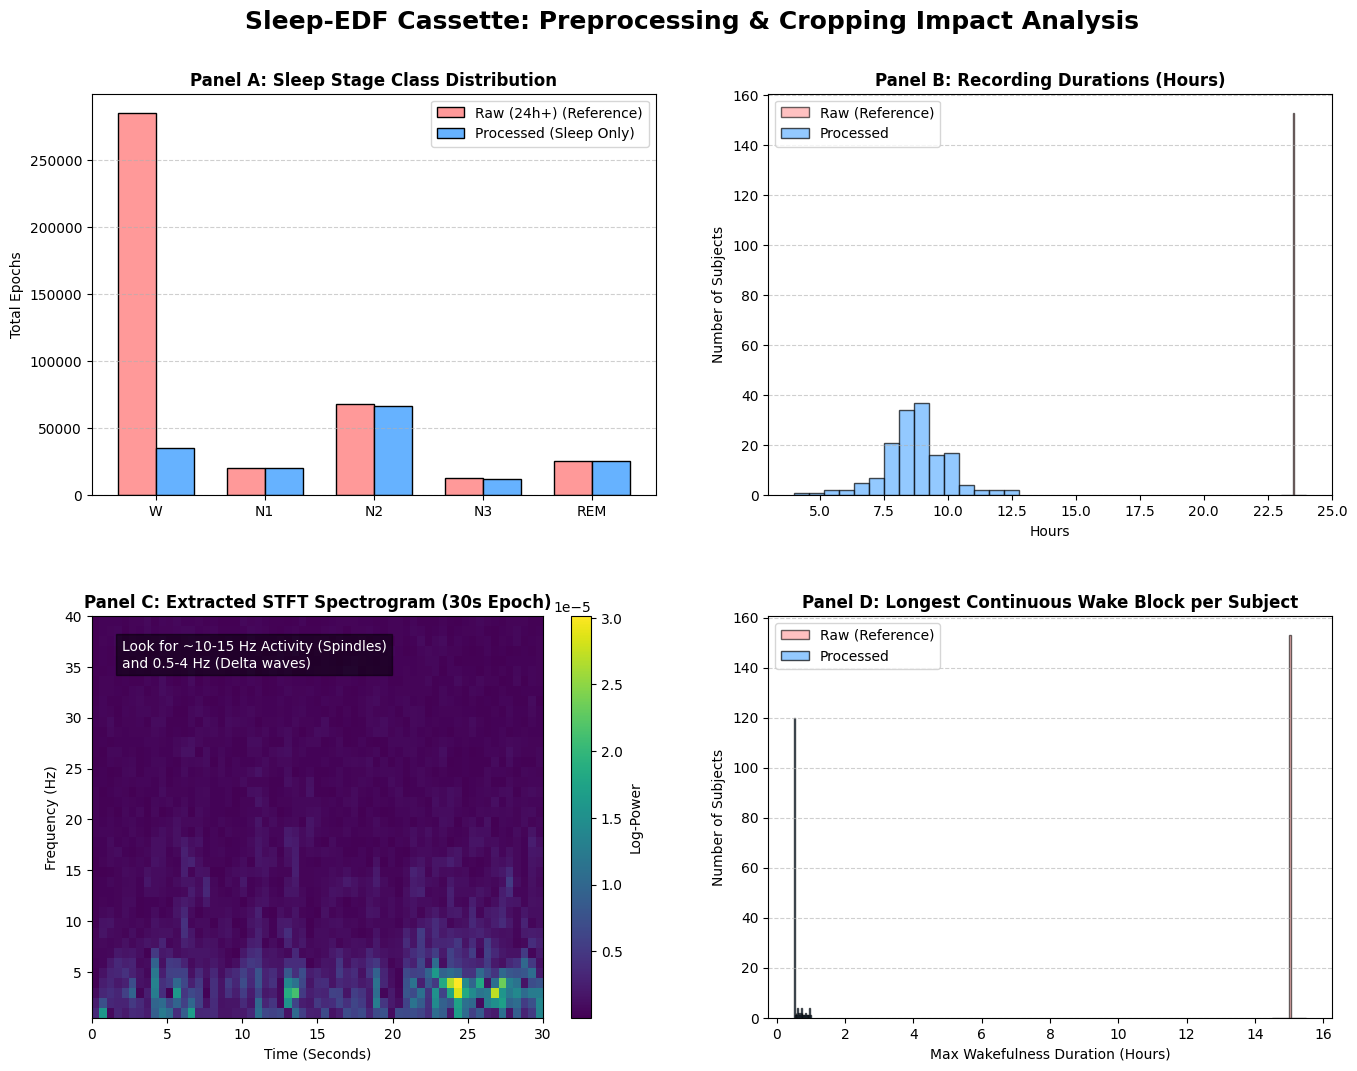

Saved preprocessing impact figure to '/kaggle/working/preprocessing_impact.pdf'


In [ ]:
generate_sleep_cassette_summary()
visualize_preprocessing_impact(PROCESSED_DATA_DIR)

**Observations.** All non-wake epochs (N1, N2, N3, REM) are preserved between the raw
and processed datasets, confirming no sleep data loss across the 153 processed
recordings. The Wake class is reduced from approximately 285,000 to 35,000 epochs,
reflecting the removal of daytime wakefulness outside the 30-minute buffer surrounding
each main sleep period.

---
> **Note — stop here for a fresh preprocessing run.** Save this version
> (`Save Version → Save & Run All`, Commit), then create a new Kaggle dataset from the
> run's Output tab (e.g., `sleep-edfx-preprocessed`). In the next session, attach that
> dataset, switch the accelerator to GPU T4, and re-open this notebook: Section 2 will
> detect the cached data automatically and Phase D will be skipped.
---

## 6. Phase B — Model Training

Switch the accelerator to GPU T4 before running the cells in this section.

### 6.1 Confirm GPU Availability

In [ ]:
assert torch.cuda.is_available(), "GPU not detected. Switch the accelerator to GPU T4 before continuing."
device = torch.device("cuda")
print(torch.cuda.get_device_name(0))


Tesla T4


### 6.2 Imports

In [ ]:
import os
import glob
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, classification_report


### 6.3 Dataset Class

Loads preprocessed spectrogram files and builds overlapping epoch sequences strictly
within each subject, so that no sequence spans two subjects and no subject appears in
more than one split.

In [ ]:
class SleepSpectrogramDataset(Dataset):
    """
    PyTorch Dataset for loading preprocessed Sleep-EDF spectrograms.
    Accepts a specific list of files to strictly prevent subject data leakage.

    `stride` controls how sequence windows are constructed within each subject:
      - stride=1 (fully overlapping) creates near-duplicate training sequences
        (adjacent windows share 4 of 5 epochs), which encourages the network to
        memorize subject-specific patterns rather than generalize.
      - stride=seq_len (non-overlapping) guarantees every epoch is scored exactly
        once, which is the correct behavior for validation/test evaluation and
        for any chronological plot built from the sequence order.

    `augment` enables light SpecAugment-style frequency/time masking, a
    train-time-only regularizer that helps close the train/validation gap.
    """
    def __init__(self, file_list, seq_len=5, stride=1, mean=None, std=None, augment=False):
        self.seq_len = seq_len
        self.stride = max(1, stride)
        self.mean = mean
        self.std = std
        self.augment = augment
        self.samples = []

        for file_path in file_list:
            try:
                archive = np.load(file_path, allow_pickle=True)
                X = archive['x']
                y = archive['y']

                if len(X.shape) == 3:
                    X = np.expand_dims(X, axis=1)  # Only triggers for legacy single-channel .npz files

                num_epochs = len(y)
                if num_epochs < seq_len:
                    continue

                # Sequence windows strictly within this subject, spaced by `stride`
                for idx in range(0, num_epochs - seq_len + 1, self.stride):
                    self.samples.append({
                        'X': X[idx : idx + seq_len],
                        'y': y[idx : idx + seq_len]
                    })
            except Exception as e:
                print(f"Error loading {file_path}: {e}")

    def __len__(self):
        return len(self.samples)

    def _spec_augment(self, X):
        """Randomly zeroes a narrow frequency band and a narrow time band per epoch."""
        X = X.copy()
        n_freq, n_time = X.shape[-2], X.shape[-1]
        for i in range(X.shape[0]):
            if np.random.rand() < 0.5:
                f_width = np.random.randint(1, max(2, n_freq // 8))
                f_start = np.random.randint(0, max(1, n_freq - f_width))
                X[i, :, f_start:f_start + f_width, :] = 0.0
            if np.random.rand() < 0.5:
                t_width = np.random.randint(1, max(2, n_time // 8))
                t_start = np.random.randint(0, max(1, n_time - t_width))
                X[i, :, :, t_start:t_start + t_width] = 0.0
        return X

    def __getitem__(self, idx):
        sample = self.samples[idx]
        X = sample['X'].copy()
        y = sample['y'].copy()

        if self.mean is not None and self.std is not None:
            X = (X - self.mean) / (self.std + 1e-8)

        if self.augment:
            X = self._spec_augment(X)

        return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long)

### 6.4 Model Architectures

A shared CNN spectrogram encoder is used across all variants. The proposed model
combines the encoder with a two-layer bidirectional LSTM over the epoch sequence;
the standalone CNN and standalone BiLSTM serve as ablation baselines.

In [ ]:
class SpectrogramCNN(nn.Module):
    def __init__(self, in_channels=3, feature_dim=128):
        super(SpectrogramCNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.fc = nn.Linear(128 * 5 * 7, feature_dim)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.pool1(x)
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.pool2(x)
        x = F.relu(self.bn3(self.conv3(x)))
        x = self.pool3(x)

        x = x.view(x.size(0), -1)
        x = F.relu(self.fc(x))
        x = self.dropout(x)
        return x

In [ ]:
class SleepCNNBiLSTM(nn.Module):
    """
    Proposed Hybrid CNN-BiLSTM Architecture
    """
    def __init__(self, in_channels=3, cnn_feature_dim=128, lstm_hidden_dim=128, num_classes=5):
        super(SleepCNNBiLSTM, self).__init__()
        self.cnn = SpectrogramCNN(in_channels=in_channels, feature_dim=cnn_feature_dim)
        self.lstm = nn.LSTM(
            input_size=cnn_feature_dim, hidden_size=lstm_hidden_dim,
            num_layers=2, batch_first=True, bidirectional=True, dropout=0.5
        )
        self.classifier = nn.Sequential(
            nn.Linear(lstm_hidden_dim * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        batch_size, seq_len, C, H, W = x.size()
        x = x.view(batch_size * seq_len, C, H, W)
        cnn_features = self.cnn(x)

        lstm_input = cnn_features.view(batch_size, seq_len, -1)
        lstm_out, _ = self.lstm(lstm_input)

        logits = self.classifier(lstm_out)
        return logits

In [ ]:
class StandaloneCNN(nn.Module):
    """
    Ablation Baseline 1: Standalone 2D CNN (No Sequential Temporal Context)
    """
    def __init__(self, in_channels=3, num_classes=5):
        super(StandaloneCNN, self).__init__()
        self.cnn = SpectrogramCNN(in_channels=in_channels, feature_dim=128)
        self.classifier = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        batch_size, seq_len, C, H, W = x.size()
        x = x.view(batch_size * seq_len, C, H, W)
        features = self.cnn(x)
        logits = self.classifier(features)
        return logits.view(batch_size, seq_len, -1)

In [ ]:
class StandaloneBiLSTM(nn.Module):
    """
    Ablation Baseline 2: Standalone BiLSTM (No Spatial Conv Filters)
    """
    def __init__(self, in_channels=3, freq_bins=40, time_steps=61, lstm_hidden_dim=128, num_classes=5):
        super(StandaloneBiLSTM, self).__init__()
        input_dim = in_channels * freq_bins * time_steps

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=lstm_hidden_dim,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.5
        )
        self.classifier = nn.Sequential(
            nn.Linear(lstm_hidden_dim * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        batch_size, seq_len, C, H, W = x.size()
        x = x.view(batch_size, seq_len, -1)
        lstm_out, _ = self.lstm(x)
        logits = self.classifier(lstm_out)
        return logits

### 6.5 Training and Evaluation Functions

In [ ]:
def train_epoch(model, dataloader, optimizer, criterion, device, clip_grad_norm=5.0):
    model.train()
    total_loss = 0
    all_preds, all_targets = [], []

    for X_batch, y_batch in dataloader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        logits = model(X_batch)

        logits = logits.view(-1, 5)
        y_batch = y_batch.view(-1)

        loss = criterion(logits, y_batch)
        loss.backward()

        if clip_grad_norm is not None:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=clip_grad_norm)

        optimizer.step()

        total_loss += loss.item()
        preds = torch.argmax(logits, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(y_batch.cpu().numpy())

    acc = accuracy_score(all_targets, all_preds)
    f1 = f1_score(all_targets, all_preds, average='macro')
    return total_loss / len(dataloader), acc, f1

In [ ]:
def evaluate_epoch(model, dataloader, criterion, device, return_detailed=False):
    model.eval()
    total_loss = 0
    all_preds, all_targets = [], []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model(X_batch)

            logits = logits.view(-1, 5)
            y_batch = y_batch.view(-1)

            loss = criterion(logits, y_batch)
            total_loss += loss.item()

            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(y_batch.cpu().numpy())

    acc = accuracy_score(all_targets, all_preds)
    f1_macro = f1_score(all_targets, all_preds, average='macro')
    f1_micro = f1_score(all_targets, all_preds, average='micro')
    kappa = cohen_kappa_score(all_targets, all_preds)

    if return_detailed:
        return total_loss / len(dataloader), acc, f1_macro, f1_micro, kappa, all_targets, all_preds

    return total_loss / len(dataloader), acc, f1_macro, kappa


In [ ]:
def train_and_save_baseline(model_instance, model_name, train_loader, val_loader, criterion, device, epochs=10, weight_decay=2e-3):
    print(f"Training {model_name} baseline model")

    optimizer = torch.optim.Adam(model_instance.parameters(), lr=1e-4, weight_decay=weight_decay)
    best_val_f1 = 0.0
    save_path = f'/kaggle/working/{model_name}_best.pth'

    for epoch in range(1, epochs + 1):
        t_loss, t_acc, t_f1 = train_epoch(model_instance, train_loader, optimizer, criterion, device)
        v_loss, v_acc, v_f1, v_kappa = evaluate_epoch(model_instance, val_loader, criterion, device)

        print(f"Epoch {epoch:02d}/{epochs} | Val Acc: {v_acc:.4f} | Val F1: {v_f1:.4f} | Val Kappa: {v_kappa:.4f}")

        if v_f1 > best_val_f1:
            best_val_f1 = v_f1
            torch.save(model_instance.state_dict(), save_path)
            print(f"  New best {model_name} checkpoint saved.")

    print(f"Finished training {model_name}.")

### 6.6 Data Splitting, Normalization, and Class Weighting

Subjects are split 70/15/15 into train/validation/test sets. Normalization statistics
and inverse-frequency class weights are computed from the training set only.

**REPRODUCIBILITY SEED SETTING**

In [ ]:
import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# Enforce deterministic behavior in PyTorch backends
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"Random seed fixed at {SEED} for reproducible weight initialization and data loading order.")

Random seed fixed at 42 for reproducible weight initialization and data loading order.


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on device: {device}")

# Use dynamic PROCESSED_DATA_DIR paths pointing to /kaggle/working/SleepData_Processed
TRAIN_DIR = os.path.join(PROCESSED_DATA_DIR, "train")
VAL_DIR   = os.path.join(PROCESSED_DATA_DIR, "val")
TEST_DIR  = os.path.join(PROCESSED_DATA_DIR, "test")

# Load files directly from split paths
train_files = sorted(glob.glob(os.path.join(TRAIN_DIR, "*.npz")))
val_files   = sorted(glob.glob(os.path.join(VAL_DIR, "*.npz")))
test_files  = sorted(glob.glob(os.path.join(TEST_DIR, "*.npz")))

assert len(train_files) > 0, f"No training files found in {TRAIN_DIR}."
assert len(val_files) > 0, f"No validation files found in {VAL_DIR}."
assert len(test_files) > 0, f"No test files found in {TEST_DIR}."

total_files = len(train_files) + len(val_files) + len(test_files)
print(f"Total Preprocessed Files Across Splits: {total_files}")
print(f"  - Train Files : {len(train_files)} ({len(train_files)/total_files*100:.1f}%)")
print(f"  - Val Files   : {len(val_files)} ({len(val_files)/total_files*100:.1f}%)")
print(f"  - Test Files  : {len(test_files)} ({len(test_files)/total_files*100:.1f}%)")

Training on device: cuda
Total Preprocessed Files Across Splits: 153
  - Train Files : 105 (68.6%)
  - Val Files   : 24 (15.7%)
  - Test Files  : 24 (15.7%)


In [ ]:
# Safety check: catch a mismatch between EEG_CHANNELS (Section 3) and whatever
# is actually saved in the attached preprocessed dataset, before spending time
# building the full Dataset objects. A stale single-channel cached dataset will
# fail this assertion loudly instead of crashing confusingly later at training time.
_probe = np.load(train_files[0])
_probe_x = _probe['x']
_probe_channels = 1 if _probe_x.ndim == 3 else _probe_x.shape[1]

assert _probe_channels == N_CHANNELS, (
    f"Attached preprocessed data has {_probe_channels} channel(s) but EEG_CHANNELS "
    f"(Section 3) expects {N_CHANNELS} ({EEG_CHANNELS}). This usually means the attached "
    f"dataset was preprocessed before the multi-channel update. Either delete/replace the "
    f"cached dataset and re-run Phase D, or set EEG_CHANNELS back to match what was used "
    f"to build the attached data."
)
print(f"Channel-count check passed: attached data has {_probe_channels} channel(s), matching EEG_CHANNELS.")


Channel-count check passed: attached data has 3 channel(s), matching EEG_CHANNELS.


In [ ]:
print("Loading datasets...")

TRAIN_STRIDE = 2   # Overlapping, but far less redundant than stride=1 (fewer near-duplicate windows)
EVAL_STRIDE = 5    # Non-overlapping (= seq_len): every validation/test epoch is scored exactly once

train_dataset = SleepSpectrogramDataset(file_list=train_files, seq_len=5, stride=TRAIN_STRIDE, augment=True)
val_dataset   = SleepSpectrogramDataset(file_list=val_files, seq_len=5, stride=EVAL_STRIDE, augment=False)
test_dataset  = SleepSpectrogramDataset(file_list=test_files, seq_len=5, stride=EVAL_STRIDE, augment=False)

print(f"Train sequences: {len(train_dataset)} (stride={TRAIN_STRIDE}, augmented) | "
      f"Val sequences: {len(val_dataset)} (stride={EVAL_STRIDE}) | "
      f"Test sequences: {len(test_dataset)} (stride={EVAL_STRIDE})")

Loading datasets...
Train sequences: 55256 (stride=2, augmented) | Val sequences: 4955 (stride=5) | Test sequences: 5018 (stride=5)


In [ ]:
print("Calculating global mean and std for normalization...")
sum_val, sum_sq, count = 0.0, 0.0, 0

for sample in train_dataset.samples:
    x = sample['X']
    sum_val += np.sum(x)
    sum_sq += np.sum(x**2)
    count += x.size

global_mean = sum_val / count
global_std = np.sqrt((sum_sq / count) - (global_mean ** 2))
print(f"Dataset Mean: {global_mean:.4f} | Dataset Std: {global_std:.4f}")

# Apply the training-set statistics across all subsets
train_dataset.mean, train_dataset.std = global_mean, global_std
val_dataset.mean, val_dataset.std     = global_mean, global_std
test_dataset.mean, test_dataset.std   = global_mean, global_std


Calculating global mean and std for normalization...
Dataset Mean: 0.0000 | Dataset Std: 0.0000


In [ ]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)


In [ ]:
print("Calculating dynamic class weights from training data...")
all_labels = []
for sample in train_dataset.samples:
    all_labels.extend(sample['y'])

class_counts = np.bincount(all_labels, minlength=5)
class_weights = 1.0 / (class_counts + 1e-8)
class_weights = class_weights / np.sum(class_weights)
weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
print(f"Calculated weights (W, N1, N2, N3, REM): {np.round(class_weights, 4)}")

criterion = nn.CrossEntropyLoss(weight=weights_tensor, label_smoothing=0.05)


Calculating dynamic class weights from training data...
Calculated weights (W, N1, N2, N3, REM): [0.1361 0.2289 0.0701 0.3861 0.1788]


### 6.7 Ablation Baseline Training

Trains the standalone CNN and standalone BiLSTM baselines for 10 epochs each, used
later for comparison against the proposed hybrid model.

In [ ]:
standalone_cnn = StandaloneCNN(in_channels=N_CHANNELS, num_classes=5).to(device)
train_and_save_baseline(standalone_cnn, "standalone_cnn", train_loader, val_loader, criterion, device, epochs=10)

standalone_lstm = StandaloneBiLSTM(in_channels=N_CHANNELS, num_classes=5).to(device)
train_and_save_baseline(standalone_lstm, "standalone_lstm", train_loader, val_loader, criterion, device, epochs=10)

Training standalone_cnn baseline model
Epoch 01/10 | Val Acc: 0.7579 | Val F1: 0.7337 | Val Kappa: 0.6782
  New best standalone_cnn checkpoint saved.
Epoch 02/10 | Val Acc: 0.7574 | Val F1: 0.7437 | Val Kappa: 0.6795
  New best standalone_cnn checkpoint saved.
Epoch 03/10 | Val Acc: 0.7809 | Val F1: 0.7589 | Val Kappa: 0.7055
  New best standalone_cnn checkpoint saved.
Epoch 04/10 | Val Acc: 0.7452 | Val F1: 0.7171 | Val Kappa: 0.6656
Epoch 05/10 | Val Acc: 0.7703 | Val F1: 0.7459 | Val Kappa: 0.6945
Epoch 06/10 | Val Acc: 0.7774 | Val F1: 0.7413 | Val Kappa: 0.7003
Epoch 07/10 | Val Acc: 0.7630 | Val F1: 0.7529 | Val Kappa: 0.6857
Epoch 08/10 | Val Acc: 0.7604 | Val F1: 0.7449 | Val Kappa: 0.6828
Epoch 09/10 | Val Acc: 0.7426 | Val F1: 0.7318 | Val Kappa: 0.6650
Epoch 10/10 | Val Acc: 0.7807 | Val F1: 0.7514 | Val Kappa: 0.7030
Finished training standalone_cnn.
Training standalone_lstm baseline model
Epoch 01/10 | Val Acc: 0.7715 | Val F1: 0.7265 | Val Kappa: 0.6860
  New best standal

### 6.8 Hybrid CNN-BiLSTM Training

Trains the proposed model for 15 epochs with a plateau learning-rate scheduler on
validation macro F1. A detailed per-class breakdown is printed every third epoch and
at the final epoch; the checkpoint with the highest validation macro F1 is saved.

In [ ]:
print("Training the proposed hybrid CNN-BiLSTM model")

model = SleepCNNBiLSTM(in_channels=N_CHANNELS, num_classes=5).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=2e-3)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=2
)

history = {
    'train_loss': [],
    'val_loss': [],
    'train_f1': [],
    'val_f1': []
}

epochs = 20
best_val_f1 = 0.0
golden_epoch = 1
class_names = ['Wake', 'N1', 'N2', 'N3', 'REM']

# Early stopping: halt once validation Macro F1 has not improved for `early_stop_patience`
# consecutive epochs, so training does not run needlessly past the generalization plateau.
early_stop_patience = 6
epochs_without_improvement = 0

Training the proposed hybrid CNN-BiLSTM model


In [ ]:
# Reproducibility and model configuration logging
def count_parameters(module):
    return sum(p.numel() for p in module.parameters() if p.requires_grad)

cnn_params = count_parameters(model.cnn)
lstm_params = sum(p.numel() for n, p in model.named_parameters() if n.startswith('lstm') and p.requires_grad)
classifier_params = count_parameters(model.classifier)
total_params = count_parameters(model)

print("Model Configuration")
print(f"  Architecture           : Hybrid CNN-BiLSTM (SleepCNNBiLSTM)")
print(f"  Input channels         : {N_CHANNELS} ({', '.join(EEG_CHANNELS)})")
print(f"  CNN feature extractor  : {cnn_params:,} trainable parameters")
print(f"  BiLSTM (2 layers)      : {lstm_params:,} trainable parameters")
print(f"  Classification head    : {classifier_params:,} trainable parameters")
print(f"  Total trainable params : {total_params:,}")
print()
print("Training Configuration")
print(f"  Random seed            : {SEED}")
print(f"  Sequence length        : 5 epochs | Train stride: {TRAIN_STRIDE} | Eval stride: {EVAL_STRIDE}")
print(f"  Batch size             : {train_loader.batch_size}")
print(f"  Optimizer              : Adam (lr=1e-4, weight_decay=2e-3)")
print(f"  LR scheduler           : ReduceLROnPlateau (mode=max, factor=0.5, patience=2)")
print(f"  Dropout                : 0.5 (CNN, BiLSTM, classifier)")
print(f"  Loss                   : Weighted Cross-Entropy (label_smoothing=0.05)")
print(f"  Gradient clipping      : max_norm=5.0")
print(f"  Data augmentation      : SpecAugment-style frequency/time masking (train only)")
print(f"  Max epochs             : {epochs} | Early-stopping patience: {early_stop_patience}")
print(f"  Device                 : {device}")


Model Configuration
  Architecture           : Hybrid CNN-BiLSTM (SleepCNNBiLSTM)
  Input channels         : 3 (EEG Fpz-Cz, EEG Pz-Oz, EOG horizontal)
  CNN feature extractor  : 667,264 trainable parameters
  BiLSTM (2 layers)      : 659,456 trainable parameters
  Classification head    : 16,773 trainable parameters
  Total trainable params : 1,343,493

Training Configuration
  Random seed            : 42
  Sequence length        : 5 epochs | Train stride: 2 | Eval stride: 5
  Batch size             : 32
  Optimizer              : Adam (lr=1e-4, weight_decay=2e-3)
  LR scheduler           : ReduceLROnPlateau (mode=max, factor=0.5, patience=2)
  Dropout                : 0.5 (CNN, BiLSTM, classifier)
  Loss                   : Weighted Cross-Entropy (label_smoothing=0.05)
  Gradient clipping      : max_norm=5.0
  Data augmentation      : SpecAugment-style frequency/time masking (train only)
  Max epochs             : 20 | Early-stopping patience: 6
  Device                 : cuda


In [ ]:
for epoch in range(epochs):
    t_loss, t_acc, t_f1 = train_epoch(model, train_loader, optimizer, criterion, device)

    is_breakdown_epoch = ((epoch + 1) % 3 == 0) or (epoch + 1 == epochs)

    if is_breakdown_epoch:
        v_loss, v_acc, v_f1, v_micro_f1, v_kappa, targets, preds = evaluate_epoch(
            model, val_loader, criterion, device, return_detailed=True
        )
    else:
        v_loss, v_acc, v_f1, v_kappa = evaluate_epoch(model, val_loader, criterion, device)

    # Step the scheduler based on validation macro F1
    scheduler.step(v_f1)

    history['train_loss'].append(t_loss)
    history['val_loss'].append(v_loss)
    history['train_f1'].append(t_f1)
    history['val_f1'].append(v_f1)

    current_lr = optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch+1:02d}/{epochs} (LR: {current_lr:.6f})")
    print(f"  Train -> Loss: {t_loss:.4f} | Acc: {t_acc:.4f} | F1: {t_f1:.4f}")
    print(f"  Val   -> Loss: {v_loss:.4f} | Acc: {v_acc:.4f} | F1: {v_f1:.4f} | Kappa: {v_kappa:.4f}")

    if is_breakdown_epoch:
        print("\n" + "-"*55)
        print(f"DETAILED VALIDATION BREAKDOWN (Epoch {epoch+1})")
        print("-"*55)
        print(f"Overall Accuracy : {v_acc:.4f}")
        print(f"Macro F1-Score   : {v_f1:.4f}")
        print(f"Micro F1-Score   : {v_micro_f1:.4f}")
        print(f"Cohen's Kappa    : {v_kappa:.4f}")
        print("\nPer-Class F1 Report:")
        report = classification_report(targets, preds, target_names=class_names, digits=4, zero_division=0)
        print(report)
        print("-"*55 + "\n")

    if v_f1 > best_val_f1:
        best_val_f1 = v_f1
        golden_epoch = epoch + 1
        epochs_without_improvement = 0
        torch.save(model.state_dict(), '/kaggle/working/best_sleep_model.pth')
        print(f"  New best validation F1 ({v_f1:.4f}). Saved checkpoint at Epoch {golden_epoch}.")
    else:
        epochs_without_improvement += 1
    print("")

    if epochs_without_improvement >= early_stop_patience:
        print(f"Early stopping triggered: no validation Macro F1 improvement for {early_stop_patience} epochs.")
        print(f"Best checkpoint remains Epoch {golden_epoch} (Val Macro F1 = {best_val_f1:.4f}).")
        break

print("Pipeline execution completed successfully.")

Epoch 01/20 (LR: 0.000100)
  Train -> Loss: 0.9083 | Acc: 0.7067 | F1: 0.6806
  Val   -> Loss: 0.7574 | Acc: 0.7730 | F1: 0.7508 | Kappa: 0.6989
  New best validation F1 (0.7508). Saved checkpoint at Epoch 1.

Epoch 02/20 (LR: 0.000100)
  Train -> Loss: 0.7592 | Acc: 0.7714 | F1: 0.7517
  Val   -> Loss: 0.7601 | Acc: 0.7798 | F1: 0.7649 | Kappa: 0.7065
  New best validation F1 (0.7649). Saved checkpoint at Epoch 2.

Epoch 03/20 (LR: 0.000100)
  Train -> Loss: 0.7340 | Acc: 0.7808 | F1: 0.7628
  Val   -> Loss: 0.7584 | Acc: 0.7753 | F1: 0.7552 | Kappa: 0.7013

-------------------------------------------------------
DETAILED VALIDATION BREAKDOWN (Epoch 3)
-------------------------------------------------------
Overall Accuracy : 0.7753
Macro F1-Score   : 0.7552
Micro F1-Score   : 0.7753
Cohen's Kappa    : 0.7013

Per-Class F1 Report:
              precision    recall  f1-score   support

        Wake     0.9243    0.7761    0.8437      5190
          N1     0.4689    0.6061    0.5287    

## 7. Model Evaluation and Visualization

### 7.1 Test-Set Inference

Runs the best hybrid checkpoint on the held-out test set to obtain ground-truth
labels, hard predictions, and class probabilities used by the figures below.

In [ ]:
import torch
import numpy as np
import torch.nn.functional as F

def get_test_predictions(model, dataloader, device):
    """
    Runs inference strictly on the unseen hold-out TEST set and extracts
    true labels, predicted class labels, and softmax probabilities.
    """
    model.eval()
    all_targets = []
    all_preds = []
    all_probs = []

    print("Running inference on hold-out TEST set to extract evaluation arrays...")
    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch = X_batch.to(device)

            # Forward pass
            logits = model(X_batch)

            # Flatten sequences to match per-epoch evaluation format
            logits = logits.view(-1, 5)
            y_batch = y_batch.view(-1)

            # Softmax probabilities and hard predictions
            probs = F.softmax(logits, dim=1)
            preds = torch.argmax(logits, dim=1)

            all_targets.extend(y_batch.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    return np.array(all_targets), np.array(all_preds), np.array(all_probs)


In [ ]:
print("Loading best checkpoint for hold-out test set evaluation...")
evaluation_model = SleepCNNBiLSTM(in_channels=N_CHANNELS, num_classes=5).to(device)
evaluation_model.load_state_dict(torch.load('/kaggle/working/best_sleep_model.pth', map_location=device))

y_true, y_pred, y_probs = get_test_predictions(evaluation_model, test_loader, device)

print("Extraction completed successfully.")
print(f"  - Ground Truth shape (y_true): {y_true.shape}")
print(f"  - Predictions shape  (y_pred): {y_pred.shape}")
print(f"  - Probabilities shape(y_probs): {y_probs.shape}")

Loading best checkpoint for hold-out test set evaluation...
Running inference on hold-out TEST set to extract evaluation arrays...
Extraction completed successfully.
  - Ground Truth shape (y_true): (25090,)
  - Predictions shape  (y_pred): (25090,)
  - Probabilities shape(y_probs): (25090, 5)


In [ ]:
# Held-out TEST-set per-class precision/recall/F1 (critique point 5: do not mix
# validation-epoch breakdowns with test-set overall metrics -- report both, clearly).
test_class_names = ['Wake', 'N1', 'N2', 'N3', 'REM']
print(f"Held-out test-set per-class classification report (Epoch {golden_epoch} checkpoint)")
print(classification_report(y_true, y_pred, target_names=test_class_names, digits=4, zero_division=0))


Held-out test-set per-class classification report (Epoch 2 checkpoint)
              precision    recall  f1-score   support

        Wake     0.8792    0.9113    0.8950      5999
          N1     0.4003    0.6595    0.4982      2840
          N2     0.8964    0.7402    0.8109     10254
          N3     0.7348    0.8617    0.7932      1916
         REM     0.8638    0.7363    0.7950      4081

    accuracy                         0.7806     25090
   macro avg     0.7549    0.7818    0.7584     25090
weighted avg     0.8185    0.7806    0.7916     25090



### 7.2 ROC Curves and Hypnogram Timeline

Two diagnostic figures are generated from the test-set predictions: stage-wise ROC
curves with per-class AUC, and a timeline comparing predicted against expert-annotated
sleep stages over a representative segment.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

def plot_multiclass_roc_curves(y_true, y_probs, class_names):
    """
    Computes and plots stage-wise ROC curves and macro-average AUC
    from actual hold-out test set probabilities and ground truths.
    """
    y_true_bin = label_binarize(y_true, classes=range(len(class_names)))
    n_classes = y_true_bin.shape[1]

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    plt.figure(figsize=(9, 7))
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

    for i, color in zip(range(n_classes), colors):
        plt.plot(fpr[i], tpr[i], color=color, lw=2.5,
                 label=f'Class {class_names[i]} (AUC = {roc_auc[i]:.3f})')

    plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Guess (AUC = 0.500)')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
    plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
    plt.title('Multiclass Stage-Wise ROC Curves (Hold-Out Test Set)', fontsize=14, fontweight='bold', pad=15)
    plt.legend(loc="lower right", fontsize=10, frameon=True)
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig('/kaggle/working/multiclass_roc.pdf', dpi=300)
    plt.show()
    print("Saved multiclass ROC plot to '/kaggle/working/multiclass_roc.pdf'")


In [ ]:
def plot_hypnogram_for_subject(model, npz_path, device, mean, std, seq_len=5, max_epochs=600):
    """
    Plots a continuous, non-overlapping chronological timeline for ONE representative
    test subject. This avoids the sliding-window duplication that would otherwise
    distort elapsed time if epochs were drawn from the globally flattened,
    overlapping test-set arrays (each epoch appearing once, in true recording order).
    """
    archive = np.load(npz_path, allow_pickle=True)
    X, y_true_full = archive['x'], archive['y']
    if X.ndim == 3:
        X = np.expand_dims(X, axis=1)

    num_epochs = len(y_true_full)
    n_windows = num_epochs // seq_len
    if n_windows == 0:
        print(f"Subject file {os.path.basename(npz_path)} has fewer than {seq_len} epochs; skipping hypnogram plot.")
        return

    X = X[: n_windows * seq_len]
    y_true_full = y_true_full[: n_windows * seq_len]
    X_norm = (X - mean) / (std + 1e-8)

    model.eval()
    preds_all = []
    with torch.no_grad():
        for w in range(n_windows):
            window = X_norm[w * seq_len : (w + 1) * seq_len]
            window_t = torch.tensor(window, dtype=torch.float32).unsqueeze(0).to(device)
            logits = model(window_t).view(-1, 5)
            preds = torch.argmax(logits, dim=1).cpu().numpy()
            preds_all.extend(preds)

    y_true_seq = y_true_full[: len(preds_all)]
    y_pred_seq = np.array(preds_all)

    subset_len = min(len(y_true_seq), max_epochs)
    stage_mapping = {0: 4, 1: 3, 2: 2, 3: 1, 4: 3.5}  # W, N1, N2, N3, REM
    time_hours = np.arange(subset_len) * 30 / 3600

    true_mapped = [stage_mapping[val] for val in y_true_seq[:subset_len]]
    pred_mapped = [stage_mapping[val] for val in y_pred_seq[:subset_len]]

    plt.figure(figsize=(14, 5))
    plt.step(time_hours, true_mapped, label='Expert Ground Truth', color='black', lw=1.8, alpha=0.8)
    plt.step(time_hours, pred_mapped, label='Model Prediction (BiLSTM)', color='#1f77b4', lw=1.5, alpha=0.85, linestyle='--')

    plt.yticks([1, 2, 3, 3.5, 4], ['N3 (Deep)', 'N2', 'N1', 'REM', 'Wake'])
    plt.xlabel('Time Elapsed (Hours)', fontsize=12, fontweight='bold')
    plt.ylabel('Sleep Stage', fontsize=12, fontweight='bold')
    plt.title(f'Continuous Sleep Macrostructure Timeline\n(Test Subject: {os.path.basename(npz_path)})',
              fontsize=14, fontweight='bold', pad=15)
    plt.legend(loc="upper right", fontsize=10, frameon=True)
    plt.grid(alpha=0.3, axis='x')
    plt.ylim(0.5, 4.5)

    plt.tight_layout()
    plt.savefig('/kaggle/working/hypnogram_timeline.pdf', dpi=300)
    plt.show()
    print(f"Saved hypnogram timeline plot to '/kaggle/working/hypnogram_timeline.pdf' "
          f"(subject epochs plotted: {subset_len}, real elapsed time: {subset_len * 30 / 3600:.2f} h)")

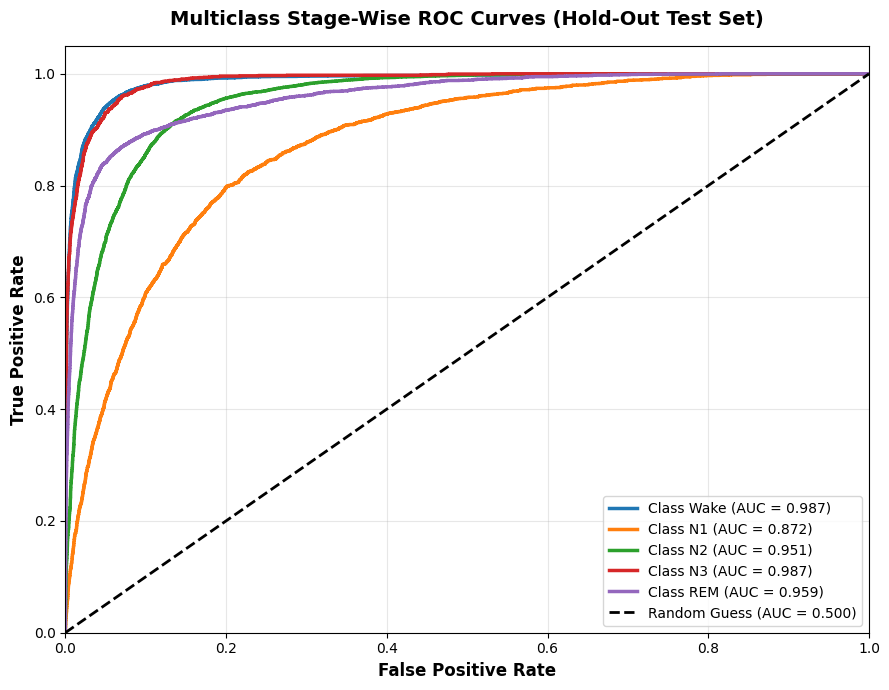

Saved multiclass ROC plot to '/kaggle/working/multiclass_roc.pdf'
Plotting hypnogram for representative test subject: SC4671_preprocessed.npz


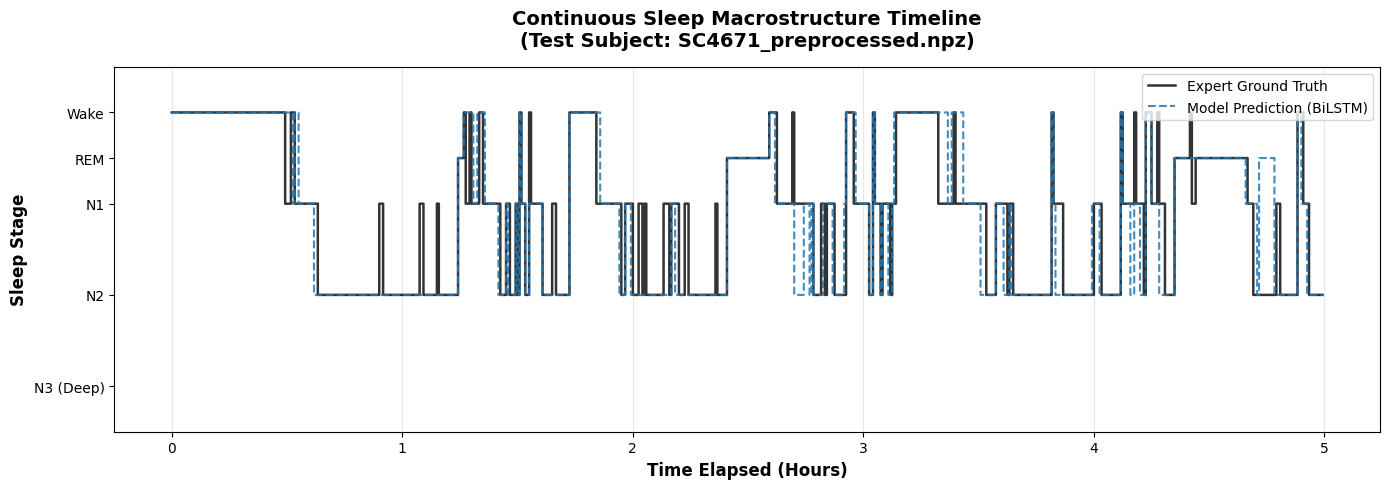

Saved hypnogram timeline plot to '/kaggle/working/hypnogram_timeline.pdf' (subject epochs plotted: 600, real elapsed time: 5.00 h)


In [ ]:
CLASS_NAMES = ['Wake', 'N1', 'N2', 'N3', 'REM']

plot_multiclass_roc_curves(y_true, y_probs, CLASS_NAMES)

# Select the longest-duration test subject for the clearest macrostructure timeline,
# and plot it directly from its own file so the timeline is a real, non-overlapping,
# chronologically ordered recording rather than a slice of the flattened test arrays.
_subject_lengths = [(f, len(np.load(f)['y'])) for f in test_files]
_longest_subject_path = max(_subject_lengths, key=lambda t: t[1])[0]
print(f"Plotting hypnogram for representative test subject: {os.path.basename(_longest_subject_path)}")

plot_hypnogram_for_subject(
    evaluation_model, _longest_subject_path, device,
    mean=train_dataset.mean, std=train_dataset.std,
    seq_len=5, max_epochs=600
)

### 7.3 Training Curves

Training and validation loss and macro F1 across epochs, with the selected checkpoint
(highest validation macro F1) marked.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_training_and_overfitting_curves(history_dict, golden_epoch_idx):
    """
    Plots dynamic training vs. validation loss and Macro F1 curves recorded during training.
    """
    epochs = list(range(1, len(history_dict['train_loss']) + 1))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # --- Plot 1: Loss Curves ---
    ax1.plot(epochs, history_dict['train_loss'], 'o-', label='Training Loss', color='#1f77b4', lw=2)
    ax1.plot(epochs, history_dict['val_loss'], 's--', label='Validation Loss', color='#ff7f0e', lw=2)
    ax1.axvline(x=golden_epoch_idx, color='gold', linestyle='-.', lw=2.5, label=f'Best Checkpoint (Epoch {golden_epoch_idx})')
    ax1.set_title('Training vs. Validation Loss', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Epochs', fontsize=11, fontweight='bold')
    ax1.set_ylabel('Cross-Entropy Loss', fontsize=11, fontweight='bold')
    ax1.legend(loc='upper right', frameon=True)
    ax1.grid(alpha=0.3)

    # --- Plot 2: Macro F1 Curves ---
    ax2.plot(epochs, history_dict['train_f1'], 'o-', label='Training Macro F1', color='#1f77b4', lw=2)
    ax2.plot(epochs, history_dict['val_f1'], 's--', label='Validation Macro F1', color='#2ca02c', lw=2)
    ax2.axvline(x=golden_epoch_idx, color='gold', linestyle='-.', lw=2.5, label=f'Best Checkpoint (Epoch {golden_epoch_idx})')
    ax2.set_title('Training vs. Validation Macro F1', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Epochs', fontsize=11, fontweight='bold')
    ax2.set_ylabel('Macro F1-Score', fontsize=11, fontweight='bold')
    ax2.legend(loc='lower right', frameon=True)
    ax2.grid(alpha=0.3)

    plt.suptitle('Model Learning Dynamics & Overfitting Tracking', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig('/kaggle/working/training_curves.pdf', dpi=300, bbox_inches='tight')
    plt.show()
    print("Saved training curves to '/kaggle/working/training_curves.pdf'")


Generating learning curves from the training run...


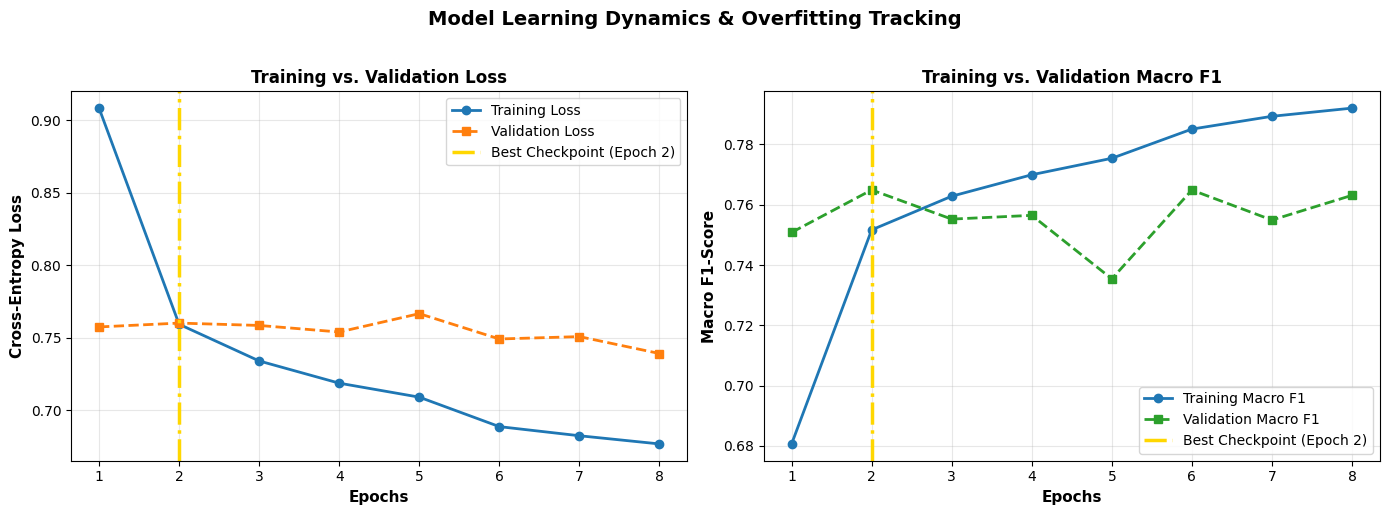

Saved training curves to '/kaggle/working/training_curves.pdf'


In [ ]:
print("Generating learning curves from the training run...")
plot_training_and_overfitting_curves(history, golden_epoch_idx=golden_epoch)


## 8. Confusion Matrix

Row-normalized confusion matrix for the hybrid model on the held-out test set.

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(model, dataloader, device, class_names):
    """Loads the best model checkpoint, runs hold-out test data, and plots a percentage heatmap."""
    print("Loading optimal model weights for test set confusion matrix evaluation...")
    model.load_state_dict(torch.load('/kaggle/working/best_sleep_model.pth', map_location=device))
    model.eval()

    all_preds = []
    all_targets = []

    print("Processing hold-out test set sequences...")
    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model(X_batch)

            logits = logits.view(-1, 5)
            y_batch = y_batch.view(-1)

            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(y_batch.cpu().numpy())

    cm = confusion_matrix(all_targets, all_preds)
    cm_perc = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_perc, annot=True, fmt=".1f", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names,
                cbar_kws={'label': 'Percentage (%)'})

    plt.title('Sleep Stage Classification Audit (Hold-Out Test Set)', fontsize=16, fontweight='bold', pad=15)
    plt.ylabel('True Sleep Stage', fontsize=12, fontweight='bold')
    plt.xlabel('Predicted Sleep Stage', fontsize=12, fontweight='bold')

    for i in range(len(class_names)):
        plt.gca().add_patch(plt.Rectangle((i, i), 1, 1, fill=False, edgecolor='darkblue', lw=3))

    plt.tight_layout()
    plt.savefig('/kaggle/working/confusion_matrix.pdf', dpi=300, bbox_inches='tight')
    plt.show()
    print("Saved confusion matrix to '/kaggle/working/confusion_matrix.pdf'")


Loading optimal model weights for test set confusion matrix evaluation...
Processing hold-out test set sequences...


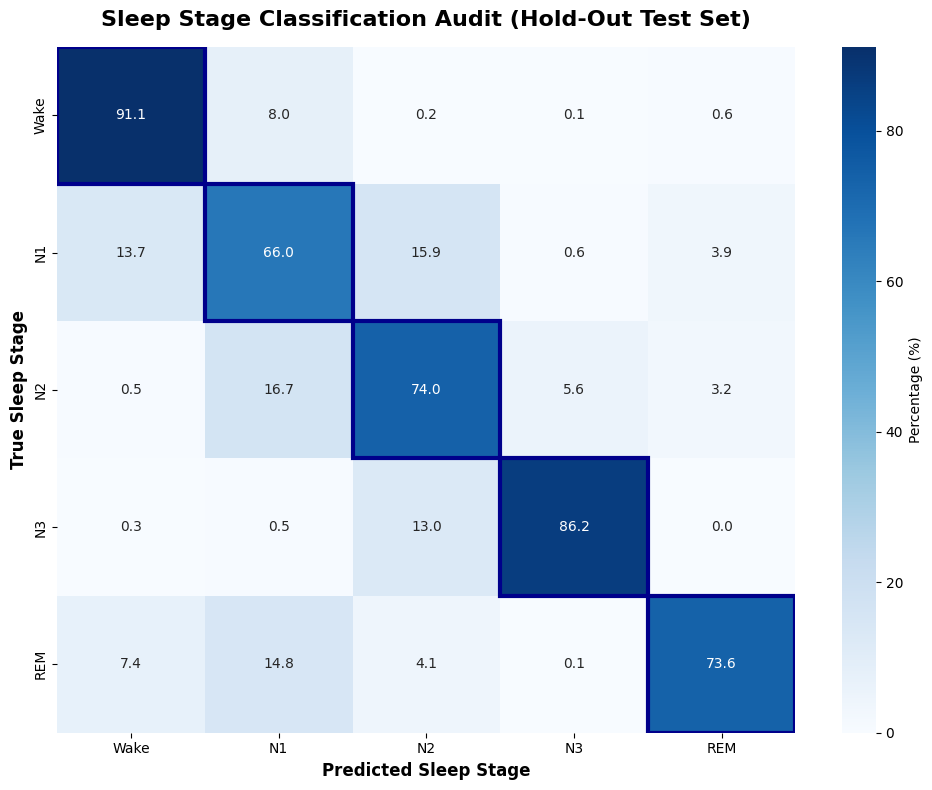

Saved confusion matrix to '/kaggle/working/confusion_matrix.pdf'


In [ ]:
LABELS = ['Wake', 'N1', 'N2', 'N3', 'REM']
plot_confusion_matrix(model, test_loader, device, LABELS)


## 9. Data-Cropping and Model-Compression Ablation Study

This section now provides direct empirical evidence for the central claim of Section 2 -- that bio-heuristic wake-cropping, not just standalone-vs-hybrid architecture choice, is responsible for balanced sleep-stage performance. It trains the identical hybrid CNN-BiLSTM architecture on the raw, **uncropped** recordings, using its own proper 70/15/15 train/validation/test split, and adds it as a fifth configuration in the same comparison figure and table used for the pruning study, alongside the standalone CNN, standalone BiLSTM, cropped hybrid, and pruned hybrid.

To isolate the effect of cropping alone, the uncropped split reuses the **same subject membership** as the cropped split (the same subjects that are in the cropped training set are also in the uncropped training set, and likewise for validation and test). This way, any performance difference between the cropped and uncropped hybrid models is attributable to the cropping treatment itself, not to a different mix of subjects.

This comparison requires the raw EDF files to still be available this session (see the `KEEP_RAW_FOR_UNCROPPED_ABLATION` toggle in Section 4.3, defaulted to `True`). If raw files are unavailable (for example, a cached-preprocessed-data-only session), this section is skipped gracefully and the figure/table fall back to the four cropped/pruned configurations only, with a clear message explaining why.

In [ ]:
import copy
import torch
import torch.nn as nn
import torch.nn.utils.prune as prune

def apply_unstructured_pruning(model, amount=0.3):
    """Applies L1 unstructured pruning to zero out weights in Conv2d and Linear layers dynamically."""
    # Create a deep copy to preserve original base weights in memory
    pruned_model = copy.deepcopy(model)
    for name, module in pruned_model.named_modules():
        if isinstance(module, (nn.Conv2d, nn.Linear)):
            prune.l1_unstructured(module, name='weight', amount=amount)
            prune.remove(module, 'weight')
    return pruned_model

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_ablation_and_pruning_study(results_dict):
    """Plots a grouped comparative bar chart evaluating actual hold-out test performance."""
    models = list(results_dict.keys())
    accuracy = [results_dict[m]['accuracy'] for m in models]
    macro_f1 = [results_dict[m]['macro_f1'] for m in models]
    kappa    = [results_dict[m]['kappa'] for m in models]

    x = np.arange(len(models))
    width = 0.25

    fig, ax = plt.subplots(figsize=(13 + 1.2 * max(0, len(models) - 4), 6))

    rects1 = ax.bar(x - width, accuracy, width, label='Accuracy', color='#1f77b4')
    rects2 = ax.bar(x, macro_f1, width, label='Macro F1-Score', color='#2ca02c')
    rects3 = ax.bar(x + width, kappa, width, label="Cohen's Kappa", color='#9467bd')

    ax.set_ylabel('Metric Score', fontsize=12, fontweight='bold')
    ax.set_title('Data-Cropping, Architectural Ablation, and Pruning Comparative Study (Test Set)',
                 fontsize=14, fontweight='bold', pad=15)
    ax.set_xticks(x)
    ax.set_xticklabels(models, fontweight='bold', fontsize=11)
    ax.legend(loc='upper right', frameon=True, fontsize=10)

    # Dynamic y-limits: the uncropped model can score very differently from the
    # cropped/pruned models (e.g. inflated accuracy, depressed macro F1), so a
    # fixed 0.50-0.90 window is not safe once a fifth, very different bar is added.
    all_vals = accuracy + macro_f1 + kappa
    ax.set_ylim(max(0.0, min(all_vals) - 0.07), min(1.0, max(all_vals) + 0.08))
    ax.grid(alpha=0.3, axis='y')

    def autolabel(rects):
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.2f}',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3),
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=9, fontweight='bold')

    autolabel(rects1)
    autolabel(rects2)
    autolabel(rects3)

    plt.tight_layout()
    plt.savefig('/kaggle/working/ablation_study.pdf', dpi=300)
    plt.show()
    print("Saved comparative ablation study chart to '/kaggle/working/ablation_study.pdf'")


### 9.1 Building an Uncropped Dataset with the Same Subject-Level Split

Re-derives the subject IDs already assigned to the train/validation/test splits (Section 4.3) and preprocesses the matching raw recordings **without** the `crop_raw_to_main_sleep` step, keeping every other part of the feature-extraction pipeline (FIR filter, STFT, log-power, frequency crop) identical.

In [ ]:
RUN_UNCROPPED_ABLATION = True
UNCROPPED_MAX_EPOCHS = 15
UNCROPPED_PATIENCE = 4

def preprocess_edf_pair_uncropped(psg_path, hyp_path, epoch_sec=30.0, sfreq=100.0):
    """Identical feature-extraction pipeline to preprocess_edf_pair, but skips wake-cropping."""
    raw = mne.io.read_raw_edf(psg_path, preload=False, verbose=False)
    raw.pick(EEG_CHANNELS)
    annotations = mne.read_annotations(hyp_path)
    raw.set_annotations(annotations, emit_warning=False)

    raw.load_data(verbose=False)
    raw.filter(l_freq=0.25, h_freq=40.0, fir_design='firwin', verbose=False)

    events, _ = mne.events_from_annotations(raw, event_id=STAGE_EVENT_ID, chunk_duration=epoch_sec)
    epochs = mne.Epochs(raw, events, event_id=STAGE_EVENT_ID, tmin=0.0,
                        tmax=epoch_sec - 1.0 / sfreq, baseline=None, preload=True,
                        on_missing='warn', verbose=False)

    data = epochs.get_data(copy=False)  # (n_epochs, N_CHANNELS, n_samples)
    labels = epochs.events[:, 2] - 1

    spectrograms = []
    for epoch in data:
        f, t, Zxx = stft(epoch, fs=sfreq, nperseg=100, noverlap=50, axis=-1)
        spec = np.log1p(np.abs(Zxx))
        freq_mask = (f >= 0.5) & (f <= 40.0)
        spectrograms.append(spec[:, freq_mask, :])

    X = np.array(spectrograms, dtype=np.float32)  # (N_epochs, N_CHANNELS, 40, 61)
    return X, labels.astype(np.int64)

In [ ]:
# Check both FULL_DATA_ROOT and explicit RAW_DATA_DIR for raw EDF files
_raw_search_path = RAW_DATA_DIR if ('RAW_DATA_DIR' in globals() and os.path.exists(RAW_DATA_DIR)) else FULL_DATA_ROOT
_raw_psg_present = len(glob.glob(os.path.join(_raw_search_path, "**", "*PSG.edf"), recursive=True)) > 0
_uncropped_ready = False

if RUN_UNCROPPED_ABLATION and _raw_psg_present:
    print(f"Building the uncropped comparison dataset using raw EDFs from {_raw_search_path}...")

    train_subject_ids = {os.path.basename(f)[:5] for f in train_files}
    val_subject_ids   = {os.path.basename(f)[:5] for f in val_files}
    test_subject_ids  = {os.path.basename(f)[:5] for f in test_files}

    raw_pairs = find_pairs(_raw_search_path)
    uncropped_dir = '/kaggle/working/uncropped_data'
    os.makedirs(uncropped_dir, exist_ok=True)

    known_ids = train_subject_ids | val_subject_ids | test_subject_ids
    for psg_path, hyp_path, sid in tqdm(raw_pairs, desc="Preprocessing (uncropped)"):
        if sid[:5] not in known_ids:
            continue
        try:
            X, y = preprocess_edf_pair_uncropped(psg_path, hyp_path)
            np.savez_compressed(os.path.join(uncropped_dir, f"{sid}_uncropped.npz"), x=X, y=y)
        except Exception as e:
            print(f"Error processing {sid} (uncropped): {e}")

    def _split_files(subject_ids):
        return [f for f in glob.glob(os.path.join(uncropped_dir, "*.npz"))
                if os.path.basename(f)[:5] in subject_ids]

    uncropped_train_files = _split_files(train_subject_ids)
    uncropped_val_files   = _split_files(val_subject_ids)
    uncropped_test_files  = _split_files(test_subject_ids)

    print(f"Uncropped recordings -> train: {len(uncropped_train_files)} | "
          f"val: {len(uncropped_val_files)} | test: {len(uncropped_test_files)}")

    _uncropped_ready = len(uncropped_train_files) > 0 and len(uncropped_val_files) > 0 and len(uncropped_test_files) > 0
    if not _uncropped_ready:
        print("Uncropped ablation skipped: one or more splits produced zero recordings.")
else:
    if not RUN_UNCROPPED_ABLATION:
        print("Uncropped ablation skipped: RUN_UNCROPPED_ABLATION is set to False.")
    else:
        print("Uncropped ablation skipped: raw EDF files could not be located.")
        print(f"Checked path: {_raw_search_path}")

Building the uncropped comparison dataset using raw EDFs from /kaggle/input/datasets/dikrahabsaoui/sc-preprocessed-230926/full_data/sleep-edfx-1.0.0/sleep-cassette...


Preprocessing (uncropped):   0%|          | 0/153 [00:00<?, ?it/s]/tmp/ipykernel_23/2835561132.py:7: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path, preload=False, verbose=False)
/tmp/ipykernel_23/2835561132.py:7: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path, preload=False, verbose=False)
/tmp/ipykernel_23/2835561132.py:7: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw = mne.io.read_raw_edf(psg_path, preload=False, verbose=False)
Preprocessing (uncropped):   1%|          | 1/153 [00:18<46:15, 18.26s/it]/tmp/ipykernel_23/2835561132.py:7: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw = mne.io.read_raw_edf(psg_path, preload=False, verbose=False)
/tmp/ipykernel_23/283556

Uncropped recordings -> train: 105 | val: 24 | test: 24


# 9.2 Training the Hybrid Model on Uncropped Data (Matched Protocol)
Uses exactly the same architecture, normalization strategy, class-weighting strategy, and validation-based checkpoint selection as the cropped hybrid model in Section 6.8. The only deliberate difference from that model is the presence of wake-cropping in the input data, which is precisely what this comparison is meant to isolate.

In [ ]:
if _uncropped_ready:
    uncropped_train_dataset = SleepSpectrogramDataset(uncropped_train_files, seq_len=5, stride=TRAIN_STRIDE, augment=True)
    uncropped_val_dataset   = SleepSpectrogramDataset(uncropped_val_files, seq_len=5, stride=EVAL_STRIDE, augment=False)
    uncropped_test_dataset  = SleepSpectrogramDataset(uncropped_test_files, seq_len=5, stride=EVAL_STRIDE, augment=False)

    _sum_val, _sum_sq, _count = 0.0, 0.0, 0
    for sample in uncropped_train_dataset.samples:
        x = sample['X']
        _sum_val += np.sum(x)
        _sum_sq += np.sum(x ** 2)
        _count += x.size
    uncropped_mean = _sum_val / _count
    uncropped_std = np.sqrt((_sum_sq / _count) - (uncropped_mean ** 2))
    print(f"Uncropped dataset mean: {uncropped_mean:.4f} | std: {uncropped_std:.4f}")

    for ds in (uncropped_train_dataset, uncropped_val_dataset, uncropped_test_dataset):
        ds.mean, ds.std = uncropped_mean, uncropped_std

    uncropped_train_loader = DataLoader(uncropped_train_dataset, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)
    uncropped_val_loader   = DataLoader(uncropped_val_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)
    uncropped_test_loader  = DataLoader(uncropped_test_dataset, batch_size=32, shuffle=False, num_workers=2, pin_memory=True)

    _uncropped_labels = []
    for s in uncropped_train_dataset.samples:
        _uncropped_labels.extend(s['y'])
    _uncropped_counts = np.bincount(_uncropped_labels, minlength=5)
    uncropped_weights = 1.0 / (_uncropped_counts + 1e-8)
    uncropped_weights = uncropped_weights / np.sum(uncropped_weights)
    uncropped_criterion = nn.CrossEntropyLoss(
        weight=torch.tensor(uncropped_weights, dtype=torch.float32).to(device), label_smoothing=0.05
    )
    print(f"Uncropped training-set class weights (W, N1, N2, N3, REM): {np.round(uncropped_weights, 4)}")
    print("(Expect Wake to dominate heavily here -- this skew is exactly what Section 2's wake-cropping removes.)")

Uncropped dataset mean: 0.0000 | std: 0.0000
Uncropped training-set class weights (W, N1, N2, N3, REM): [0.0194 0.2557 0.0804 0.4353 0.2092]
(Expect Wake to dominate heavily here -- this skew is exactly what Section 2's wake-cropping removes.)


In [ ]:
if _uncropped_ready:
    print("Training the hybrid CNN-BiLSTM model on UNCROPPED data...")

    uncropped_model = SleepCNNBiLSTM(in_channels=N_CHANNELS, num_classes=5).to(device)
    uncropped_optimizer = torch.optim.Adam(uncropped_model.parameters(), lr=1e-4, weight_decay=2e-3)
    uncropped_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        uncropped_optimizer, mode='max', factor=0.5, patience=2
    )

    uncropped_best_val_f1 = 0.0
    uncropped_golden_epoch = 1
    _uncropped_epochs_without_improvement = 0

    # History dictionary to log metrics across training
    uncropped_history = {'train_loss': [], 'val_loss': [], 'train_f1': [], 'val_f1': []}

    for epoch in range(UNCROPPED_MAX_EPOCHS):
        t_loss, t_acc, t_f1 = train_epoch(uncropped_model, uncropped_train_loader, uncropped_optimizer, uncropped_criterion, device)
        v_loss, v_acc, v_f1, v_kappa = evaluate_epoch(uncropped_model, uncropped_val_loader, uncropped_criterion, device)
        uncropped_scheduler.step(v_f1)

        uncropped_history['train_loss'].append(t_loss)
        uncropped_history['val_loss'].append(v_loss)
        uncropped_history['train_f1'].append(t_f1)
        uncropped_history['val_f1'].append(v_f1)

        print(f"[Uncropped] Epoch {epoch+1:02d}/{UNCROPPED_MAX_EPOCHS} | "
              f"Train Loss: {t_loss:.4f} Acc: {t_acc:.4f} F1: {t_f1:.4f} | "
              f"Val Loss: {v_loss:.4f} Acc: {v_acc:.4f} F1: {v_f1:.4f} Kappa: {v_kappa:.4f}")

        if v_f1 > uncropped_best_val_f1:
            uncropped_best_val_f1 = v_f1
            uncropped_golden_epoch = epoch + 1
            _uncropped_epochs_without_improvement = 0
            torch.save(uncropped_model.state_dict(), '/kaggle/working/uncropped_hybrid_best.pth')
            print(f"  New best UNCROPPED validation F1 ({v_f1:.4f}). Saved checkpoint at Epoch {uncropped_golden_epoch}.")
        else:
            _uncropped_epochs_without_improvement += 1

        if _uncropped_epochs_without_improvement >= UNCROPPED_PATIENCE:
            print(f"Early stopping (uncropped): no validation Macro F1 improvement for {UNCROPPED_PATIENCE} epochs.")
            break

    print(f"Uncropped training complete. Best checkpoint: Epoch {uncropped_golden_epoch} (Val Macro F1 = {uncropped_best_val_f1:.4f}).")

Training the hybrid CNN-BiLSTM model on UNCROPPED data...
[Uncropped] Epoch 01/15 | Train Loss: 1.0389 Acc: 0.8509 F1: 0.6818 | Val Loss: 1.3228 Acc: 0.8685 F1: 0.7608 Kappa: 0.7566
  New best UNCROPPED validation F1 (0.7608). Saved checkpoint at Epoch 1.
[Uncropped] Epoch 02/15 | Train Loss: 0.9269 Acc: 0.8864 F1: 0.7593 | Val Loss: 1.2860 Acc: 0.8718 F1: 0.7307 Kappa: 0.7587
[Uncropped] Epoch 03/15 | Train Loss: 0.9066 Acc: 0.8926 F1: 0.7709 | Val Loss: 1.3065 Acc: 0.8334 F1: 0.7345 Kappa: 0.7015
[Uncropped] Epoch 04/15 | Train Loss: 0.8963 Acc: 0.8950 F1: 0.7750 | Val Loss: 1.2751 Acc: 0.8915 F1: 0.7776 Kappa: 0.7940
  New best UNCROPPED validation F1 (0.7776). Saved checkpoint at Epoch 4.
[Uncropped] Epoch 05/15 | Train Loss: 0.8854 Acc: 0.8978 F1: 0.7811 | Val Loss: 1.3236 Acc: 0.8577 F1: 0.7480 Kappa: 0.7408
[Uncropped] Epoch 06/15 | Train Loss: 0.8827 Acc: 0.8983 F1: 0.7820 | Val Loss: 1.3040 Acc: 0.8494 F1: 0.7540 Kappa: 0.7245
[Uncropped] Epoch 07/15 | Train Loss: 0.8754 Acc: 

# 9.2.1 Diagnostic Visualizations for Uncropped Model
Generates test-set ROC curves, full-night hypnogram timeline, training curves, and normalized confusion matrix strictly for the model trained on uncropped recordings to reveal majority-class dominance and inter-class dynamics.

Test-Set Inference & Multiclass ROC Curves

Extracting uncropped test set predictions and probabilities...


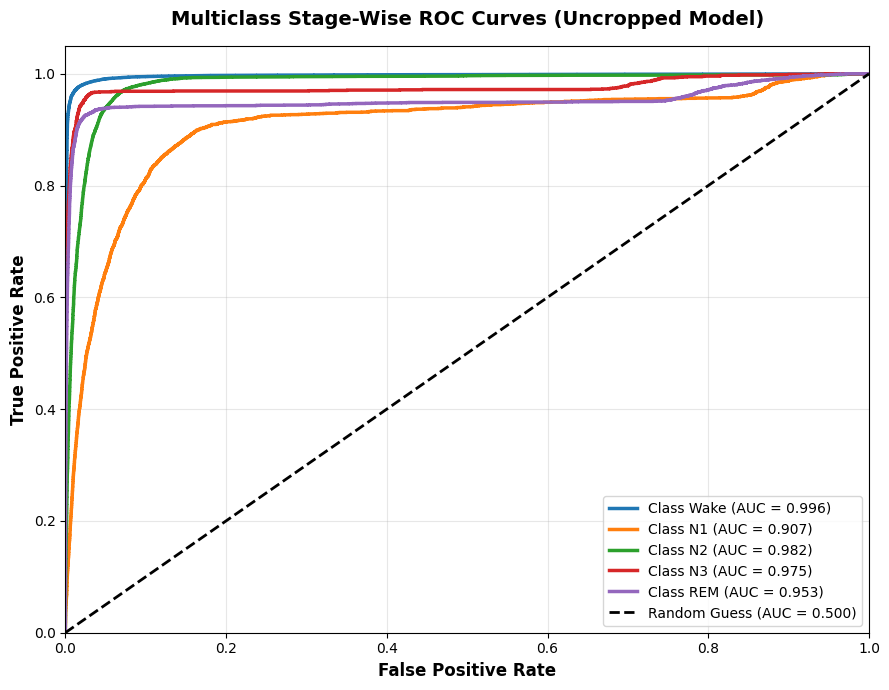

Saved uncropped ROC plot to '/kaggle/working/uncropped_multiclass_roc.pdf'


In [ ]:
if _uncropped_ready:
    import numpy as np
    import matplotlib.pyplot as plt
    import torch.nn.functional as F
    from sklearn.preprocessing import label_binarize
    from sklearn.metrics import roc_curve, auc

    print("Extracting uncropped test set predictions and probabilities...")
    uncropped_eval_model = SleepCNNBiLSTM(in_channels=N_CHANNELS, num_classes=5).to(device)
    uncropped_eval_model.load_state_dict(torch.load('/kaggle/working/uncropped_hybrid_best.pth', map_location=device))
    uncropped_eval_model.eval()

    unc_targets_list, unc_probs_list = [], []
    with torch.no_grad():
        for X_batch, y_batch in uncropped_test_loader:
            X_batch = X_batch.to(device)
            logits = uncropped_eval_model(X_batch).view(-1, 5)
            probs = F.softmax(logits, dim=1)

            unc_targets_list.extend(y_batch.view(-1).cpu().numpy())
            unc_probs_list.extend(probs.cpu().numpy())

    unc_y_true = np.array(unc_targets_list)
    unc_y_probs = np.array(unc_probs_list)

    # Plot Multiclass ROC
    class_names = ['Wake', 'N1', 'N2', 'N3', 'REM']
    y_true_bin = label_binarize(unc_y_true, classes=range(len(class_names)))

    plt.figure(figsize=(9, 7))
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']

    for i, color in enumerate(colors):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], unc_y_probs[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, color=color, lw=2.5, label=f'Class {class_names[i]} (AUC = {roc_auc:.3f})')

    plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Guess (AUC = 0.500)')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=12, fontweight='bold')
    plt.ylabel('True Positive Rate', fontsize=12, fontweight='bold')
    plt.title('Multiclass Stage-Wise ROC Curves (Uncropped Model)', fontsize=14, fontweight='bold', pad=15)
    plt.legend(loc="lower right", fontsize=10, frameon=True)
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig('/kaggle/working/uncropped_multiclass_roc.pdf', dpi=300)
    plt.show()
    print("Saved uncropped ROC plot to '/kaggle/working/uncropped_multiclass_roc.pdf'")

Continuous Sleep Macrostructure Hypnogram

Plotting hypnogram for uncropped test subject: SC4002_uncropped.npz


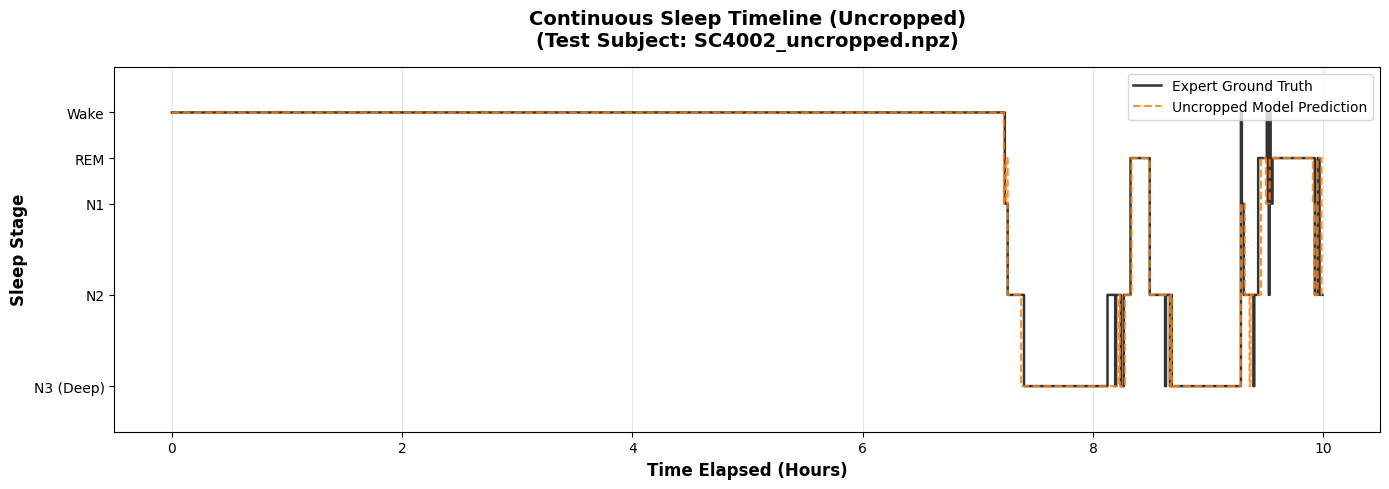

Saved uncropped hypnogram timeline plot to '/kaggle/working/uncropped_hypnogram_timeline.pdf'


In [ ]:
if _uncropped_ready:
    # Select longest uncropped test subject recording
    _unc_subject_lengths = [(f, len(np.load(f)['y'])) for f in uncropped_test_files]
    _longest_unc_subject_path = max(_unc_subject_lengths, key=lambda t: t[1])[0]
    print(f"Plotting hypnogram for uncropped test subject: {os.path.basename(_longest_unc_subject_path)}")

    def plot_uncropped_hypnogram(model, npz_path, device, mean, std, seq_len=5, max_epochs=1200):
        archive = np.load(npz_path, allow_pickle=True)
        X, y_true_full = archive['x'], archive['y']
        if X.ndim == 3:
            X = np.expand_dims(X, axis=1)

        num_epochs = len(y_true_full)
        n_windows = num_epochs // seq_len
        if n_windows == 0:
            return

        X = X[: n_windows * seq_len]
        y_true_full = y_true_full[: n_windows * seq_len]
        X_norm = (X - mean) / (std + 1e-8)

        model.eval()
        preds_all = []
        with torch.no_grad():
            for w in range(n_windows):
                window = X_norm[w * seq_len : (w + 1) * seq_len]
                window_t = torch.tensor(window, dtype=torch.float32).unsqueeze(0).to(device)
                logits = model(window_t).view(-1, 5)
                preds = torch.argmax(logits, dim=1).cpu().numpy()
                preds_all.extend(preds)

        subset_len = min(len(preds_all), max_epochs)
        stage_mapping = {0: 4, 1: 3, 2: 2, 3: 1, 4: 3.5}  # W, N1, N2, N3, REM
        time_hours = np.arange(subset_len) * 30 / 3600

        true_mapped = [stage_mapping[val] for val in y_true_full[:subset_len]]
        pred_mapped = [stage_mapping[val] for val in preds_all[:subset_len]]

        plt.figure(figsize=(14, 5))
        plt.step(time_hours, true_mapped, label='Expert Ground Truth', color='black', lw=1.8, alpha=0.8)
        plt.step(time_hours, pred_mapped, label='Uncropped Model Prediction', color='#ff7f0e', lw=1.5, alpha=0.85, linestyle='--')

        plt.yticks([1, 2, 3, 3.5, 4], ['N3 (Deep)', 'N2', 'N1', 'REM', 'Wake'])
        plt.xlabel('Time Elapsed (Hours)', fontsize=12, fontweight='bold')
        plt.ylabel('Sleep Stage', fontsize=12, fontweight='bold')
        plt.title(f'Continuous Sleep Timeline (Uncropped)\n(Test Subject: {os.path.basename(npz_path)})',
                  fontsize=14, fontweight='bold', pad=15)
        plt.legend(loc="upper right", fontsize=10, frameon=True)
        plt.grid(alpha=0.3, axis='x')
        plt.ylim(0.5, 4.5)

        plt.tight_layout()
        plt.savefig('/kaggle/working/uncropped_hypnogram_timeline.pdf', dpi=300)
        plt.show()

    plot_uncropped_hypnogram(
        uncropped_eval_model, _longest_unc_subject_path, device,
        mean=uncropped_mean, std=uncropped_std, seq_len=5, max_epochs=1200
    )
    print("Saved uncropped hypnogram timeline plot to '/kaggle/working/uncropped_hypnogram_timeline.pdf'")

Training & Validation Learning Dynamics

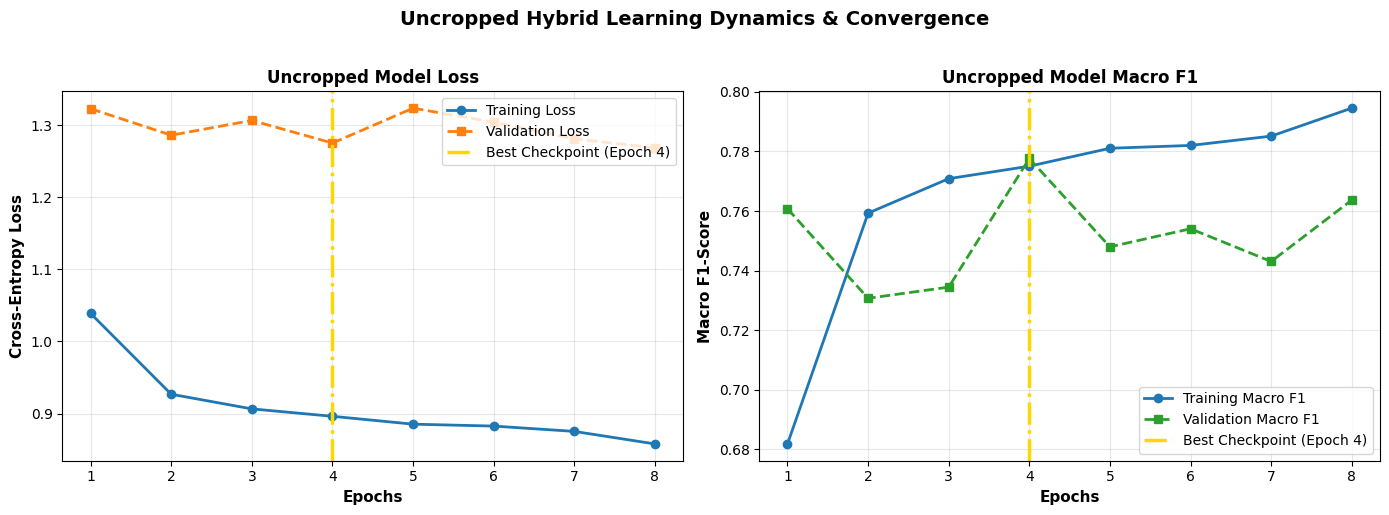

Saved uncropped training curves to '/kaggle/working/uncropped_training_curves.pdf'


In [ ]:
if _uncropped_ready:
    epochs = list(range(1, len(uncropped_history['train_loss']) + 1))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Loss Curves
    ax1.plot(epochs, uncropped_history['train_loss'], 'o-', label='Training Loss', color='#1f77b4', lw=2)
    ax1.plot(epochs, uncropped_history['val_loss'], 's--', label='Validation Loss', color='#ff7f0e', lw=2)
    ax1.axvline(x=uncropped_golden_epoch, color='gold', linestyle='-.', lw=2.5, label=f'Best Checkpoint (Epoch {uncropped_golden_epoch})')
    ax1.set_title('Uncropped Model Loss', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Epochs', fontsize=11, fontweight='bold')
    ax1.set_ylabel('Cross-Entropy Loss', fontsize=11, fontweight='bold')
    ax1.legend(loc='upper right', frameon=True)
    ax1.grid(alpha=0.3)

    # Macro F1 Curves
    ax2.plot(epochs, uncropped_history['train_f1'], 'o-', label='Training Macro F1', color='#1f77b4', lw=2)
    ax2.plot(epochs, uncropped_history['val_f1'], 's--', label='Validation Macro F1', color='#2ca02c', lw=2)
    ax2.axvline(x=uncropped_golden_epoch, color='gold', linestyle='-.', lw=2.5, label=f'Best Checkpoint (Epoch {uncropped_golden_epoch})')
    ax2.set_title('Uncropped Model Macro F1', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Epochs', fontsize=11, fontweight='bold')
    ax2.set_ylabel('Macro F1-Score', fontsize=11, fontweight='bold')
    ax2.legend(loc='lower right', frameon=True)
    ax2.grid(alpha=0.3)

    plt.suptitle('Uncropped Hybrid Learning Dynamics & Convergence', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig('/kaggle/working/uncropped_training_curves.pdf', dpi=300, bbox_inches='tight')
    plt.show()
    print("Saved uncropped training curves to '/kaggle/working/uncropped_training_curves.pdf'")

Normalized Confusion Matrix Heatmap

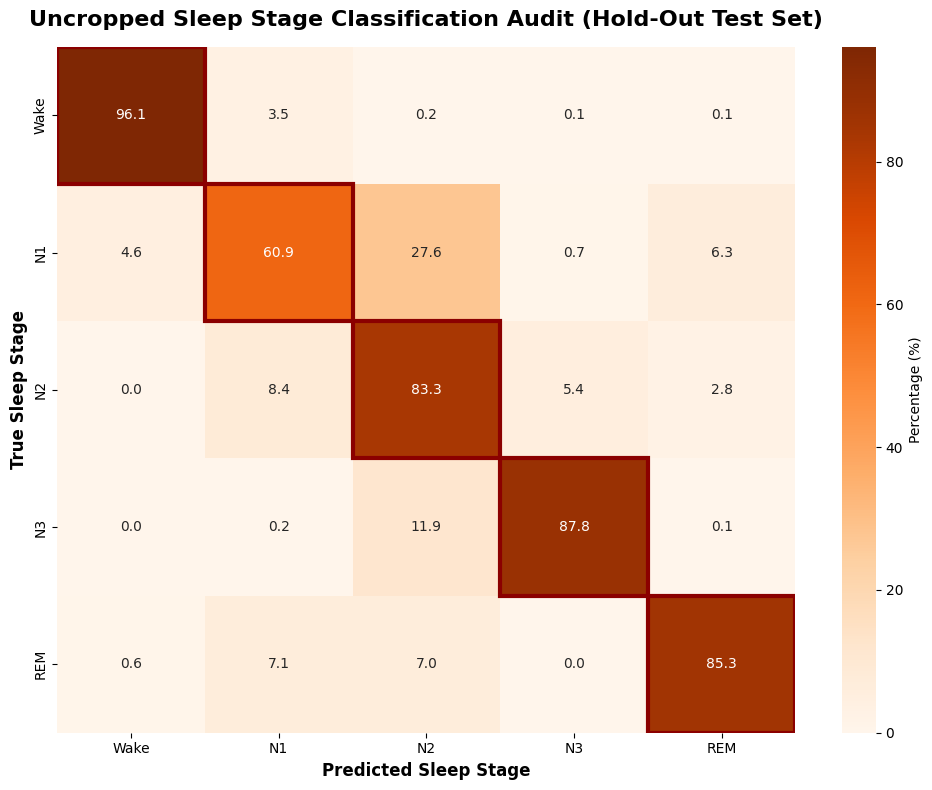

Saved uncropped confusion matrix to '/kaggle/working/uncropped_confusion_matrix.pdf'


In [ ]:
if _uncropped_ready:
    import seaborn as sns
    from sklearn.metrics import confusion_matrix

    unc_preds = np.argmax(unc_y_probs, axis=1)
    cm = confusion_matrix(unc_y_true, unc_preds)
    cm_perc = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm_perc, annot=True, fmt=".1f", cmap="Oranges",
                xticklabels=class_names, yticklabels=class_names,
                cbar_kws={'label': 'Percentage (%)'})

    plt.title('Uncropped Sleep Stage Classification Audit (Hold-Out Test Set)', fontsize=16, fontweight='bold', pad=15)
    plt.ylabel('True Sleep Stage', fontsize=12, fontweight='bold')
    plt.xlabel('Predicted Sleep Stage', fontsize=12, fontweight='bold')

    for i in range(len(class_names)):
        plt.gca().add_patch(plt.Rectangle((i, i), 1, 1, fill=False, edgecolor='darkred', lw=3))

    plt.tight_layout()
    plt.savefig('/kaggle/working/uncropped_confusion_matrix.pdf', dpi=300, bbox_inches='tight')
    plt.show()
    print("Saved uncropped confusion matrix to '/kaggle/working/uncropped_confusion_matrix.pdf'")

Uncropped Model Test-Set Classification Report

In [ ]:

if _uncropped_ready:
    from sklearn.metrics import classification_report

    test_class_names = ['Wake', 'N1', 'N2', 'N3', 'REM']
    unc_preds = np.argmax(unc_y_probs, axis=1)

    print(f"Held-out test-set per-class classification report (Uncropped Model - Epoch {uncropped_golden_epoch} Checkpoint):")
    print(classification_report(unc_y_true, unc_preds, target_names=test_class_names, digits=4, zero_division=0))

Held-out test-set per-class classification report (Uncropped Model - Epoch 4 Checkpoint):
              precision    recall  f1-score   support

        Wake     0.9961    0.9609    0.9782     44951
          N1     0.4049    0.6085    0.4862      3078
          N2     0.8581    0.8333    0.8455     10693
          N3     0.7281    0.8785    0.7962      1917
         REM     0.8624    0.8527    0.8575      4086

    accuracy                         0.9138     64725
   macro avg     0.7699    0.8268    0.7927     64725
weighted avg     0.9288    0.9138    0.9198     64725



# 9.3 Evaluating All Five Configurations on Their Held-Out Test Sets
The standalone CNN, standalone BiLSTM, cropped hybrid, and pruned hybrid are evaluated on the cropped held-out test set. The uncropped hybrid is evaluated on its own uncropped held-out test set, using its own best checkpoint selected by validation Macro F1. The two test sets contain the same held-out subjects, so the comparison isolates the effect of wake-cropping rather than any difference in who is being evaluated.

In [ ]:
print("Evaluating all variants on their respective held-out test sets")

# Helper to unpack evaluate_epoch whether it returns 4 values or 7 values (when return_detailed=True)
def run_eval(model, loader, crit):
    res = evaluate_epoch(model, loader, crit, device)
    # Loss, Accuracy, Macro F1, Cohen's Kappa
    return res[1], res[2], res[3]

# 1. Standalone CNN (cropped)
cnn_model = StandaloneCNN().to(device)
cnn_model.load_state_dict(torch.load('/kaggle/working/standalone_cnn_best.pth', map_location=device))
cnn_acc, cnn_f1, cnn_kappa = run_eval(cnn_model, test_loader, criterion)

# 2. Standalone BiLSTM (cropped)
lstm_model = StandaloneBiLSTM().to(device)
lstm_model.load_state_dict(torch.load('/kaggle/working/standalone_lstm_best.pth', map_location=device))
lstm_acc, lstm_f1, lstm_kappa = run_eval(lstm_model, test_loader, criterion)

# 3. Dense Hybrid CNN-BiLSTM (cropped -- proposed base model)
hybrid_model = SleepCNNBiLSTM().to(device)
hybrid_model.load_state_dict(torch.load('/kaggle/working/best_sleep_model.pth', map_location=device))
hybrid_acc, hybrid_f1, hybrid_kappa = run_eval(hybrid_model, test_loader, criterion)

# 4. Pruned Hybrid (30%, cropped) -- deepcopy first so pruning does not mutate
# hybrid_model in place (it previously did, making pruned_hybrid and hybrid_model
# the same object; this only produced correct numbers because hybrid_model's own
# metrics happened to be computed earlier in this cell, before pruning ran).
import copy
pruned_hybrid = apply_unstructured_pruning(copy.deepcopy(hybrid_model), amount=0.3)
pruned_acc, pruned_f1, pruned_kappa = run_eval(pruned_hybrid, test_loader, criterion)

test_ablation_results = {
    'Standalone CNN': {'accuracy': cnn_acc, 'macro_f1': cnn_f1, 'kappa': cnn_kappa},
    'Standalone LSTM': {'accuracy': lstm_acc, 'macro_f1': lstm_f1, 'kappa': lstm_kappa},
    'Dense Hybrid (Ours)': {'accuracy': hybrid_acc, 'macro_f1': hybrid_f1, 'kappa': hybrid_kappa},
    'Pruned Hybrid (30%)': {'accuracy': pruned_acc, 'macro_f1': pruned_f1, 'kappa': pruned_kappa},
}

# 5. Hybrid trained on UNCROPPED data, evaluated on its own uncropped test set
if _uncropped_ready:
    best_uncropped_model = SleepCNNBiLSTM(in_channels=N_CHANNELS, num_classes=5).to(device)
    best_uncropped_model.load_state_dict(torch.load('/kaggle/working/uncropped_hybrid_best.pth', map_location=device))

    # Detailed output for classification report
    eval_out = evaluate_epoch(best_uncropped_model, uncropped_test_loader, uncropped_criterion, device, return_detailed=True)
    unc_acc, unc_f1, unc_kappa = eval_out[1], eval_out[2], eval_out[4]
    unc_targets, unc_preds = eval_out[5], eval_out[6]

    test_ablation_results['Hybrid (Uncropped)'] = {'accuracy': unc_acc, 'macro_f1': unc_f1, 'kappa': unc_kappa}

    print("\nUncropped-hybrid held-out test per-class report:")
    print(classification_report(unc_targets, unc_preds, target_names=['Wake', 'N1', 'N2', 'N3', 'REM'], digits=4, zero_division=0))
else:
    print("\nNote: 'Hybrid (Uncropped)' is not included this run -- raw EDF files were not available.")
    print("Attach the raw dataset with KEEP_RAW_FOR_UNCROPPED_ABLATION = True and re-run Phase D to include it.")

Evaluating all variants on their respective held-out test sets


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/rnn.py:1141: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at /pytorch/aten/src/ATen/native/cudnn/RNN.cpp:1480.)
  result = _VF.lstm(



Uncropped-hybrid held-out test per-class report:
              precision    recall  f1-score   support

        Wake     0.9961    0.9609    0.9782     44951
          N1     0.4049    0.6085    0.4862      3078
          N2     0.8581    0.8333    0.8455     10693
          N3     0.7281    0.8785    0.7962      1917
         REM     0.8624    0.8527    0.8575      4086

    accuracy                         0.9138     64725
   macro avg     0.7699    0.8268    0.7927     64725
weighted avg     0.9288    0.9138    0.9198     64725



In [ ]:
print(f"{'Model Variant':<22} | {'Accuracy':<10} | {'Macro F1':<10} | {'Kappa':<10}")
print("-" * 65)
for model_name, metrics in test_ablation_results.items():
    print(f"{model_name:<22} | {metrics['accuracy']:.4f}     | {metrics['macro_f1']:.4f}     | {metrics['kappa']:.4f}")
print("-" * 65)

if 'Hybrid (Uncropped)' in test_ablation_results:
    delta_acc = test_ablation_results['Dense Hybrid (Ours)']['accuracy'] - test_ablation_results['Hybrid (Uncropped)']['accuracy']
    delta_f1 = test_ablation_results['Dense Hybrid (Ours)']['macro_f1'] - test_ablation_results['Hybrid (Uncropped)']['macro_f1']
    delta_kappa = test_ablation_results['Dense Hybrid (Ours)']['kappa'] - test_ablation_results['Hybrid (Uncropped)']['kappa']
    print(f"\nCropped minus Uncropped (Dense Hybrid): "
          f"Accuracy {delta_acc:+.4f} | Macro F1 {delta_f1:+.4f} | Kappa {delta_kappa:+.4f}")

Model Variant          | Accuracy   | Macro F1   | Kappa     
-----------------------------------------------------------------
Standalone CNN         | 0.7880     | 0.7571     | 0.7150
Standalone LSTM        | 0.7804     | 0.7492     | 0.7056
Dense Hybrid (Ours)    | 0.7806     | 0.7584     | 0.7084
Pruned Hybrid (30%)    | 0.7878     | 0.7646     | 0.7167
Hybrid (Uncropped)     | 0.9138     | 0.7927     | 0.8275
-----------------------------------------------------------------

Cropped minus Uncropped (Dense Hybrid): Accuracy -0.1331 | Macro F1 -0.0343 | Kappa -0.1190


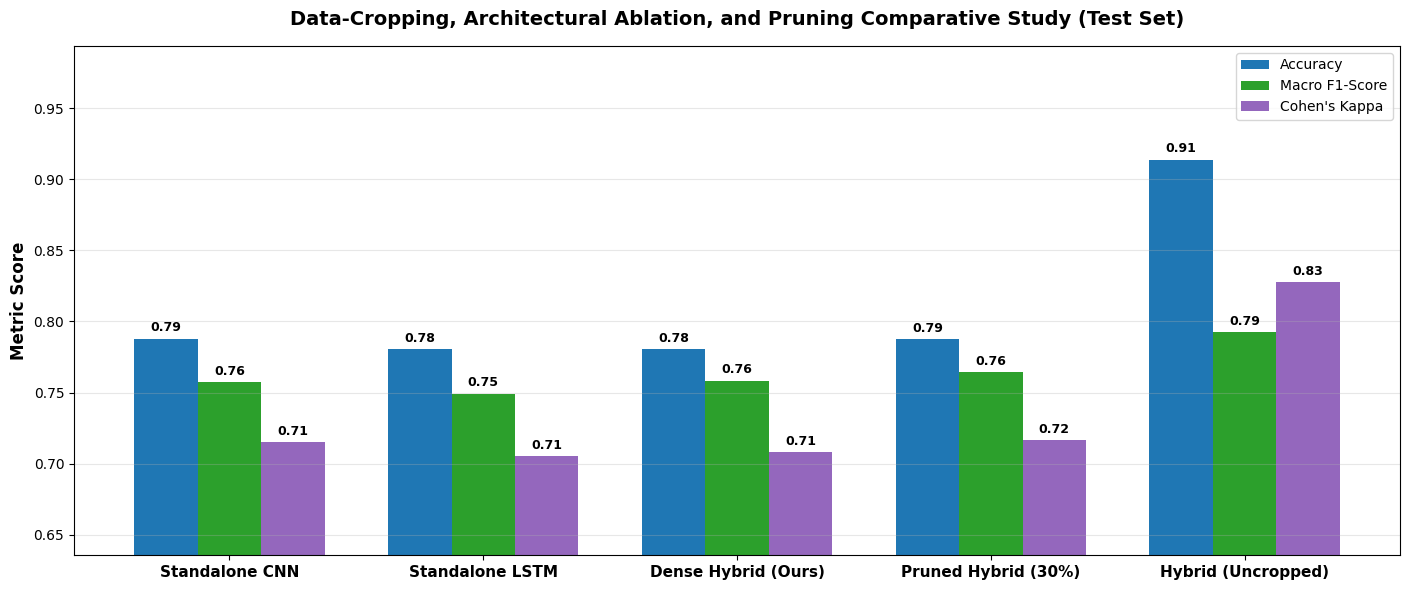

Saved comparative ablation study chart to '/kaggle/working/ablation_study.pdf'


In [ ]:
plot_ablation_and_pruning_study(test_ablation_results)